# Measuring Matter Antimatter Asymmetries at the Large Hadron Collider

**Changes by Giacomo (2026-10-06)** — every change in the code starts with a `# [Giacomo, 2026-10-06]` comment:
- `lhcb_freq.py`: veto window of the $\chi_{c0}$ at ±60 MeV; fixed the condition in `scan_config`.
- settings cell: data path configurable with `LHCB_DATA_DIR`.
- preselection scan: starts from `data_loose` (cuts looser than the grid), not from the already preselected sample.
- notes (without changing the results) on the systematic study (Barlow, common rule), the signal-region scan, the selection of the Dalitz region.

**Changes by Giacomo (2026-10-07)** — every change starts with `# [Giacomo, 2026-10-07]`:
- significance of $A\neq0$ as $Z=\sqrt{t}$ (convention for a likelihood ratio with one parameter, as in the report), not `norm.ppf(1-p)`;
- coverage of the Wilks interval on $A$ alone ($\mu$ and the other parameters profiled, $\chi^2_1$ threshold at 68.3%), with the nominal window, to compare it with the Bayesian credible interval on $A$;
- $A_{\rm raw}$ from sideband subtraction (fourth estimator, compared with the fit);
- charm vetoes in the two agreed versions ($D^0$ only; $D^0+J/\psi+\chi_{c0}$);
- clean-up: removed the $\pi\pi\pi$ preselection (not used), the empty template cells and the to-do list; corrected the value of $\mu$ in the text of the joint fit; notebook re-run top to bottom.


In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import CenteredNorm
import scipy.stats

import lhcb_freq as lf   # functions + settings live in lhcb_freq.py

/opt/homebrew/Caskroom/miniforge/base/envs/cern/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# All the settings in one place (fit window, signal region, preselection cuts, n. of exponentials, limits, ...)
# [Giacomo, 2026-10-06] configurable data path: the environment variable LHCB_DATA_DIR if defined,
# otherwise the data directory of the repository ([Giacomo, 2026-10-07]).
import os
_DATA = Path(os.environ.get("LHCB_DATA_DIR", "../../opendata-project/Data"))
cfg = lf.Config(
    data_dir=_DATA,
    sim_file=_DATA / "PhaseSpaceSimulation.root",
)
cfg

Config(data_dir=PosixPath('/Users/gmoretti/Work/fededegu_martiborsa/LHCb/opendata-project/Data'), data_files=('B2HHH_MagnetDown.root', 'B2HHH_MagnetUp.root'), data_tree='DecayTree', sim_file=PosixPath('/Users/gmoretti/Work/fededegu_martiborsa/LHCb/opendata-project/Data/PhaseSpaceSimulation.root'), sim_tree='PhaseSpaceTree', n_products=3, m_K=493.677, m_Pi=139.57039, m_B=5279.41, prob_k_min=0.5, prob_pi_max=0.5, prob_pi_min=0.5, prob_k_max=0.5, fit_window=(5100.0, 5600.0), sig_region=(5200.0, 5350.0), n_exp=2, mass_hypothesis='kaon', bkg_shape='charge', bkg_yield='free', signal='gauss', signal_per_charge=False, limits={'N_sig': (0, None), 'N_bkg': (0, None), 'A_CP': (-1.0, 1.0), 'sigma': (1.0, 100.0), 'lam': (1e-06, 1.0), 'f_bkgs': (0.0, 1.0), 'beta': (0.3, 5.0), 'm_cb': (1.01, 50.0)})

## Simulation Data

In [3]:
df_sim = lf.load_tree(cfg.sim_file, cfg.sim_tree)
print(df_sim.columns.tolist())
df_sim.head()

['B_FlightDistance', 'B_VertexChi2', 'H1_PX', 'H1_PY', 'H1_PZ', 'H1_ProbK', 'H1_ProbPi', 'H1_Charge', 'H1_IPChi2', 'H1_isMuon', 'H2_PX', 'H2_PY', 'H2_PZ', 'H2_ProbK', 'H2_ProbPi', 'H2_Charge', 'H2_IPChi2', 'H2_isMuon', 'H3_PX', 'H3_PY', 'H3_PZ', 'H3_ProbK', 'H3_ProbPi', 'H3_Charge', 'H3_IPChi2', 'H3_isMuon']


,B_FlightDistance,B_VertexChi2,H1_PX,H1_PY,H1_PZ,H1_ProbK,H1_ProbPi,H1_Charge,H1_IPChi2,H1_isMuon,...,H2_IPChi2,H2_isMuon,H3_PX,H3_PY,H3_PZ,H3_ProbK,H3_ProbPi,H3_Charge,H3_IPChi2,H3_isMuon
0,0.0,1.0,3551.84,1636.96,23904.14,1.0,0.0,-1,1.0,0,...,1.0,0,36100.40,16546.83,295600.61,1.0,0.0,-1,1.0,0
1,0.0,1.0,-2525.98,-5284.05,35822.00,1.0,0.0,1,1.0,0,...,1.0,0,-8648.32,-16617.56,98535.13,1.0,0.0,-1,1.0,0
2,0.0,1.0,-700.67,1299.73,8127.76,1.0,0.0,-1,1.0,0,...,1.0,0,-13483.34,10860.77,79787.59,1.0,0.0,1,1.0,0
3,0.0,1.0,3364.63,1397.30,222815.29,1.0,0.0,1,1.0,0,...,1.0,0,1925.16,-551.12,40420.96,1.0,0.0,1,1.0,0
4,0.0,1.0,-581.66,-1305.24,22249.59,1.0,0.0,-1,1.0,0,...,1.0,0,-2820.04,-8305.43,250130.00,1.0,0.0,-1,1.0,0


### Data exploration

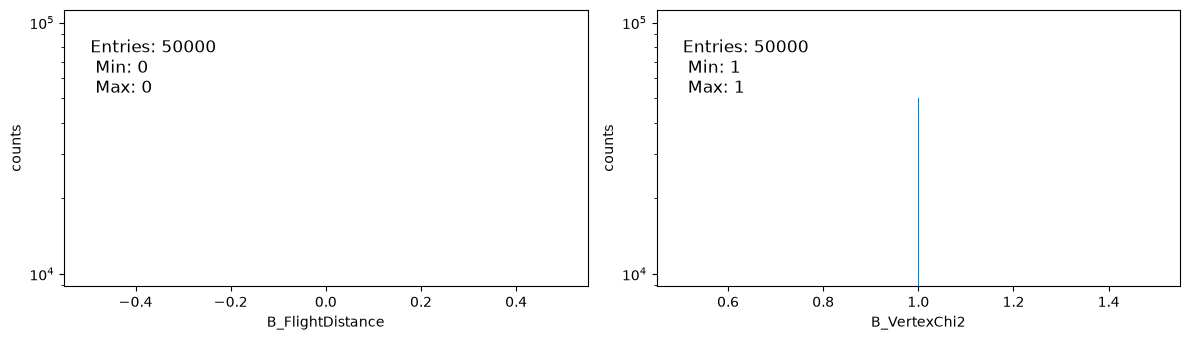

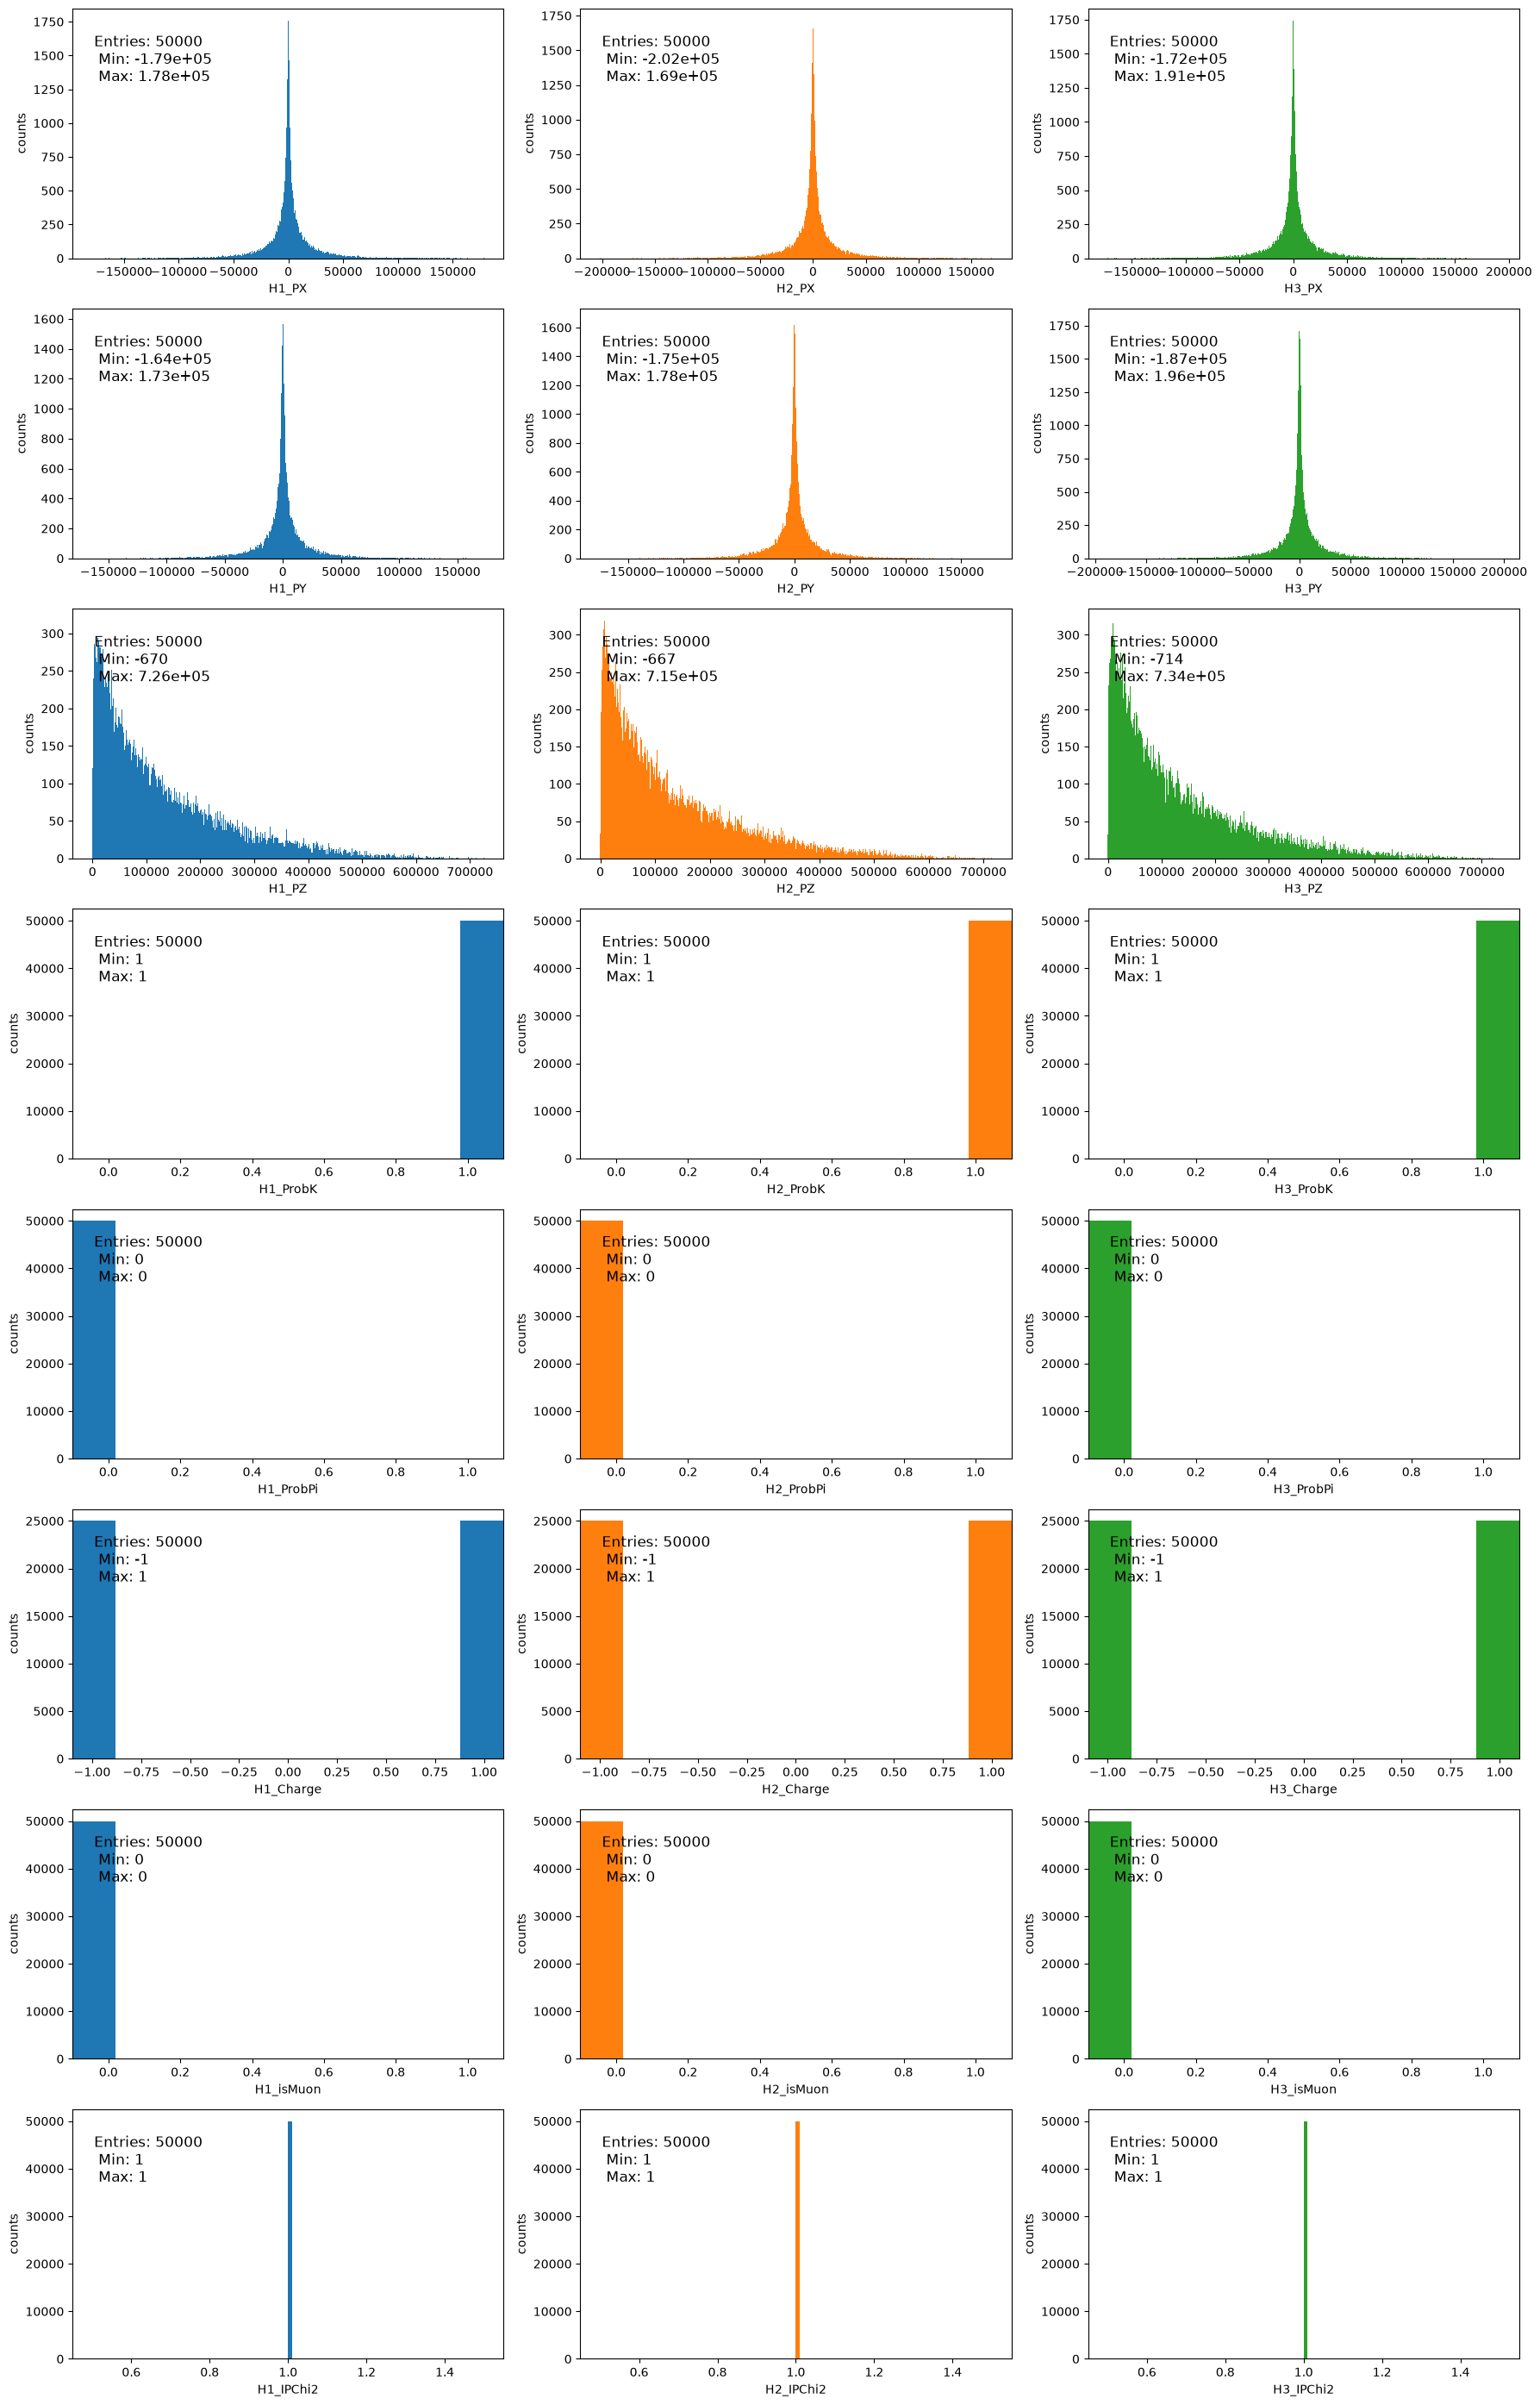

In [4]:
figs = lf.plot_all_features(df_sim, lf.GLOBAL_FEATURES, lf.PRODUCT_FEATURES + lf.EXTRA_PRODUCT_FEATURES,
                            lf.PLOT_SETTINGS["sim"], cfg.n_products)

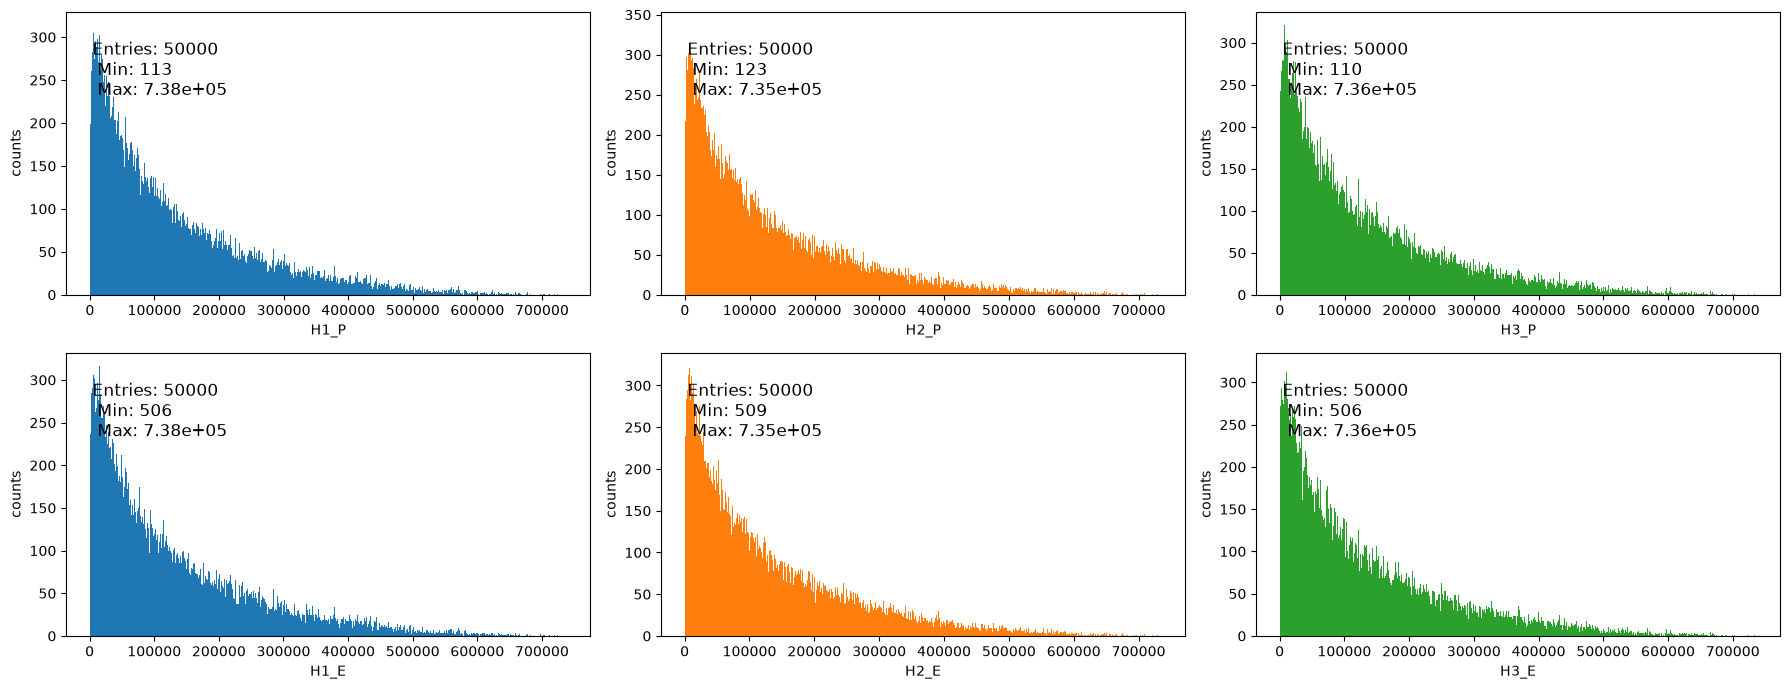

In [5]:
# New features: momentum magnitude and energy of each product
lf.add_kinematics(df_sim, cfg)
figs = lf.plot_all_features(df_sim, product_features=["P", "E"], settings=lf.PLOT_SETTINGS["sim"], n_products=cfg.n_products)

### Compute Invariant Mass

In [6]:
lf.add_B_variables(df_sim, cfg)      # adds B_Mass and B_Charge
df_sim[["B_Mass", "B_Charge"]].describe()

,B_Mass,B_Charge
count,50000.000000,50000.00000
mean,5267.883223,0.00000
std,80.964681,1.00001
min,2909.905221,-1.00000
25%,5279.241654,-1.00000
50%,5279.248254,0.00000
75%,5279.253599,1.00000
max,5279.279077,1.00000


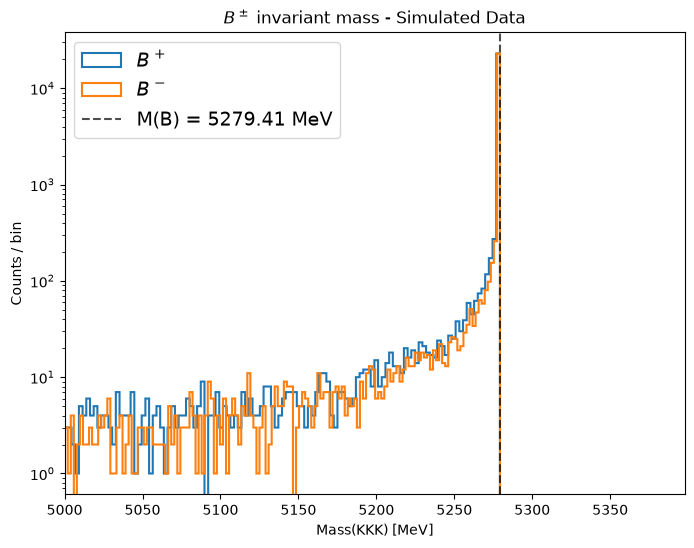

In [7]:
lf.plot_mass_by_charge(df_sim, cfg, bins=1000, logy=True, xlim=(5000, None),
                       title=r"$B^\pm$ invariant mass - Simulated Data");

max |m_vector - m_numpy| = 2.7284841053187847e-12 MeV


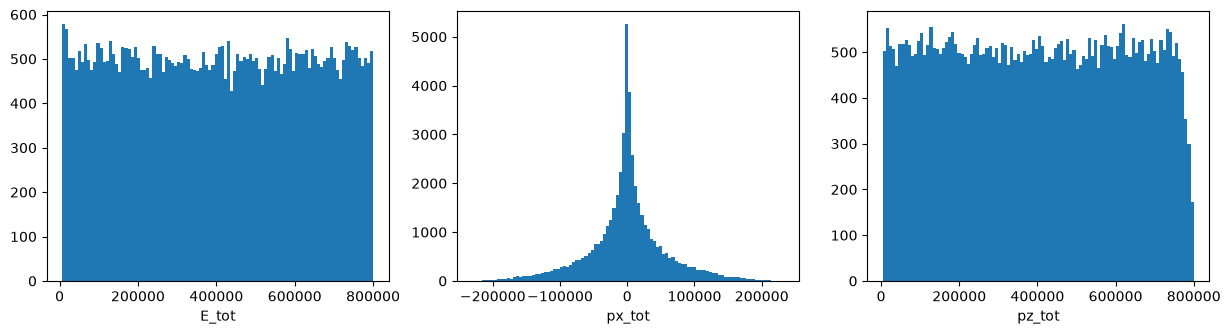

In [8]:
# Independent cross-check of the `vector` result with plain numpy (energy/momentum conservation, m^2 = E^2 - p^2)
E_tot = sum(np.sqrt(sum(df_sim[f"H{i}_{c}"]**2 for c in ("PX", "PY", "PZ")) + cfg.m_K**2) for i in cfg.particles)
p_tot = {c: sum(df_sim[f"H{i}_{c}"] for i in cfg.particles) for c in ("PX", "PY", "PZ")}
m_manual = np.sqrt(E_tot**2 - sum(v**2 for v in p_tot.values()))
print("max |m_vector - m_numpy| =", np.abs(m_manual - df_sim["B_Mass"]).max(), "MeV")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, (name, v) in zip(axes, {"E_tot": E_tot, "px_tot": p_tot["PX"], "pz_tot": p_tot["PZ"]}.items()):
    ax.hist(v, bins=100)
    ax.set_xlabel(name)

# Real Data

#### Load Data

In [9]:
all_data = lf.load_data(cfg)
print("total events read:", len(all_data))
all_data.head()

total events read: 8556118


,B_FlightDistance,B_VertexChi2,H1_PX,H1_PY,H1_PZ,H1_ProbK,H1_ProbPi,H1_Charge,H1_IPChi2,H1_isMuon,...,H2_isMuon,H3_PX,H3_PY,H3_PZ,H3_ProbK,H3_ProbPi,H3_Charge,H3_IPChi2,H3_isMuon,magnet
0,25.301004,1.497280,375.284205,831.308481,51820.233718,0.038616,0.888755,-1,212.776776,0,...,0,-208.210960,-2586.359121,105848.271681,0.193004,0.138845,1,61.157888,1,down
1,94.690700,1.383338,-4985.130785,5853.750057,326157.454706,0.073556,0.039064,-1,373.815885,1,...,1,-175.018535,1325.178792,87681.561846,0.080397,0.758603,1,185.092016,0,down
2,8.284490,5.187101,-1265.456544,2330.050788,90762.658032,0.030095,0.636693,1,53.187855,0,...,0,-1383.996490,-71.081104,85574.929582,0.750751,0.399602,-1,1.481413,0,down
3,5.590769,7.129099,-720.797259,3413.790588,86793.058768,0.211414,0.350969,-1,6.232666,0,...,0,398.775944,-1134.914464,14653.316611,0.005698,0.964705,1,468.174038,0,down
4,3.013242,10.988701,397.754571,1791.373059,40040.364159,0.005697,0.933102,-1,3.137287,0,...,0,477.148467,2113.439057,24462.076980,0.002979,0.918983,1,60.530372,0,down


#### Data Exploration

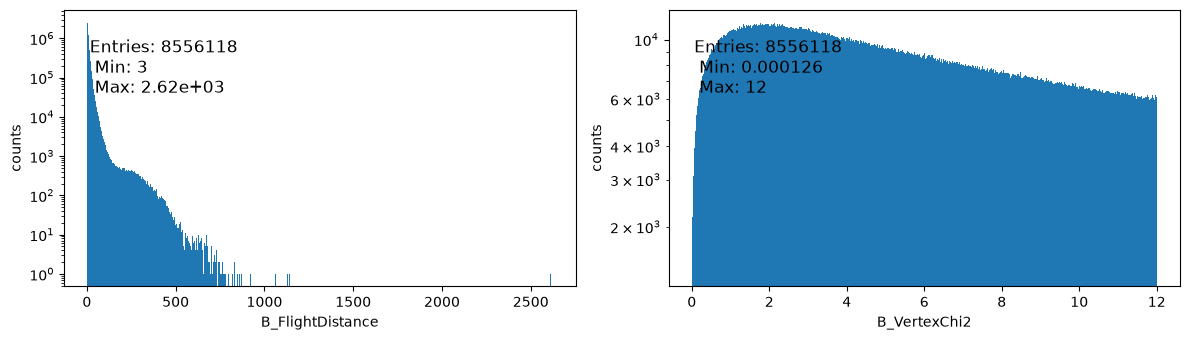

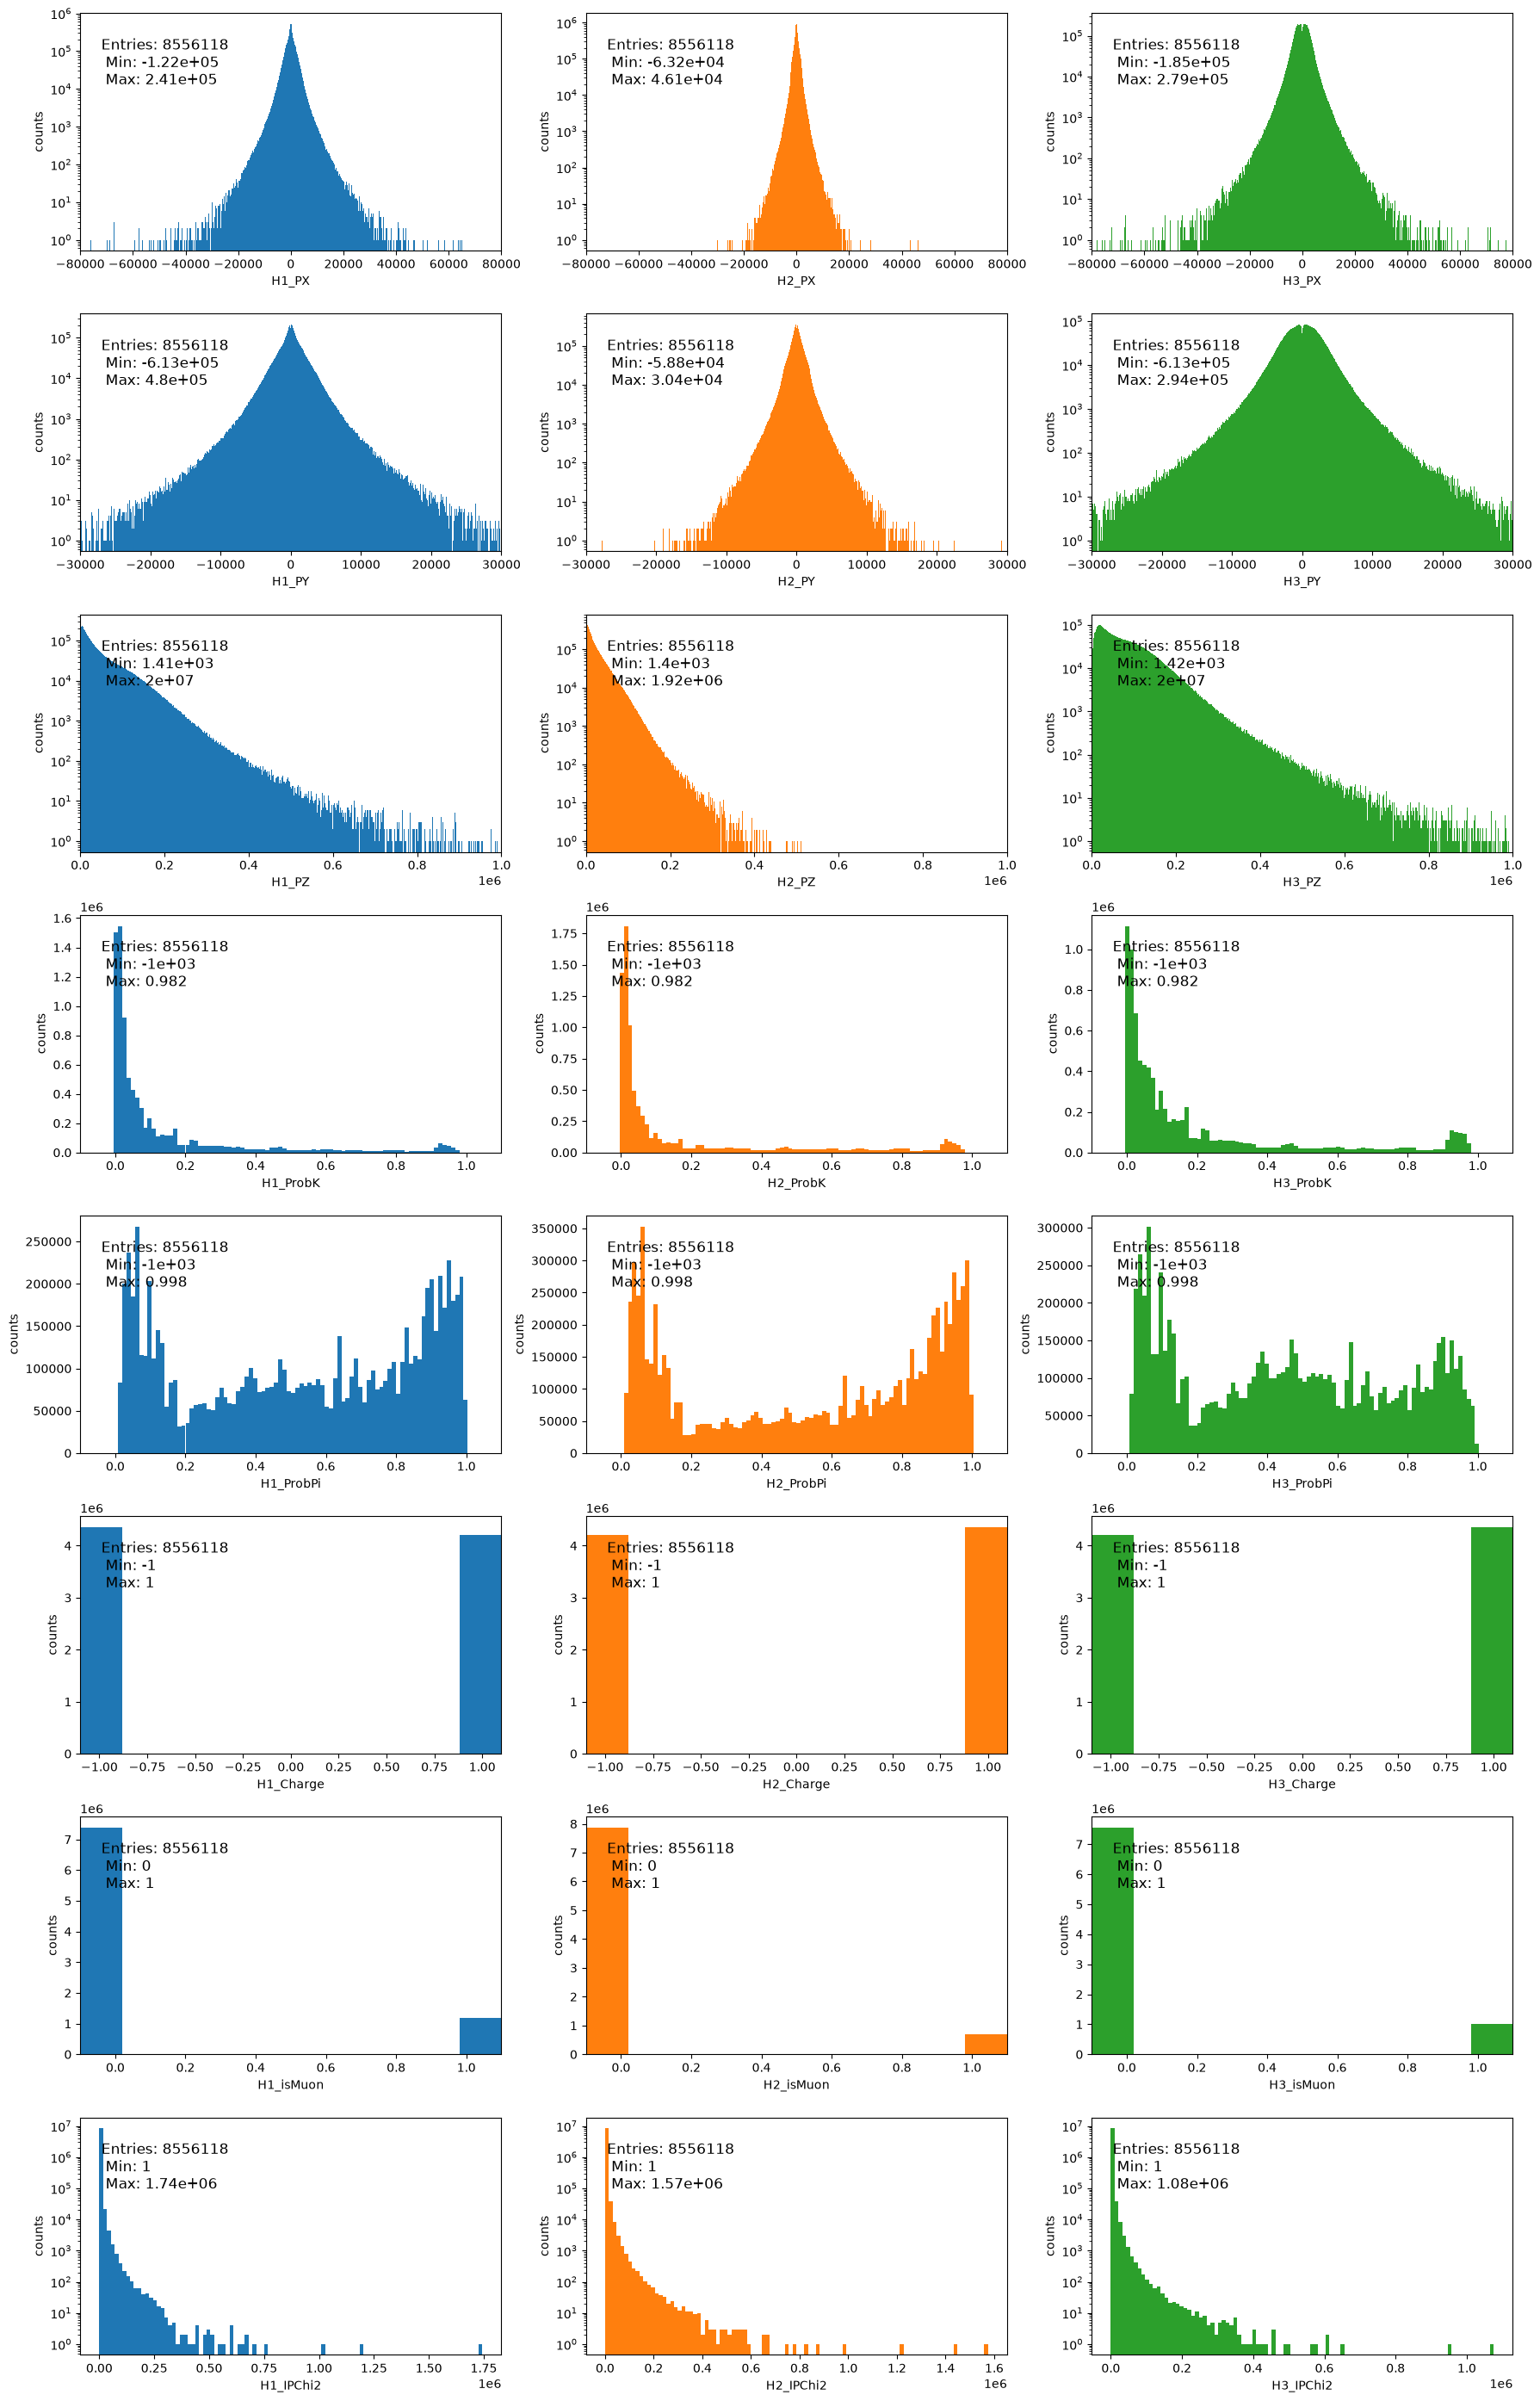

In [10]:
figs = lf.plot_all_features(all_data, lf.GLOBAL_FEATURES, lf.PRODUCT_FEATURES + lf.EXTRA_PRODUCT_FEATURES,
                            lf.PLOT_SETTINGS["raw"], cfg.n_products)

In [11]:
# keep only the columns needed by the analysis
data = all_data[cfg.columns].copy()
del all_data
print(data.columns.tolist())

['H1_PX', 'H1_PY', 'H1_PZ', 'H1_ProbK', 'H1_ProbPi', 'H1_Charge', 'H1_isMuon', 'H2_PX', 'H2_PY', 'H2_PZ', 'H2_ProbK', 'H2_ProbPi', 'H2_Charge', 'H2_isMuon', 'H3_PX', 'H3_PY', 'H3_PZ', 'H3_ProbK', 'H3_ProbPi', 'H3_Charge', 'H3_isMuon', 'magnet']


### Preselection (B -> KKK)

preselection efficiency: 0.28%


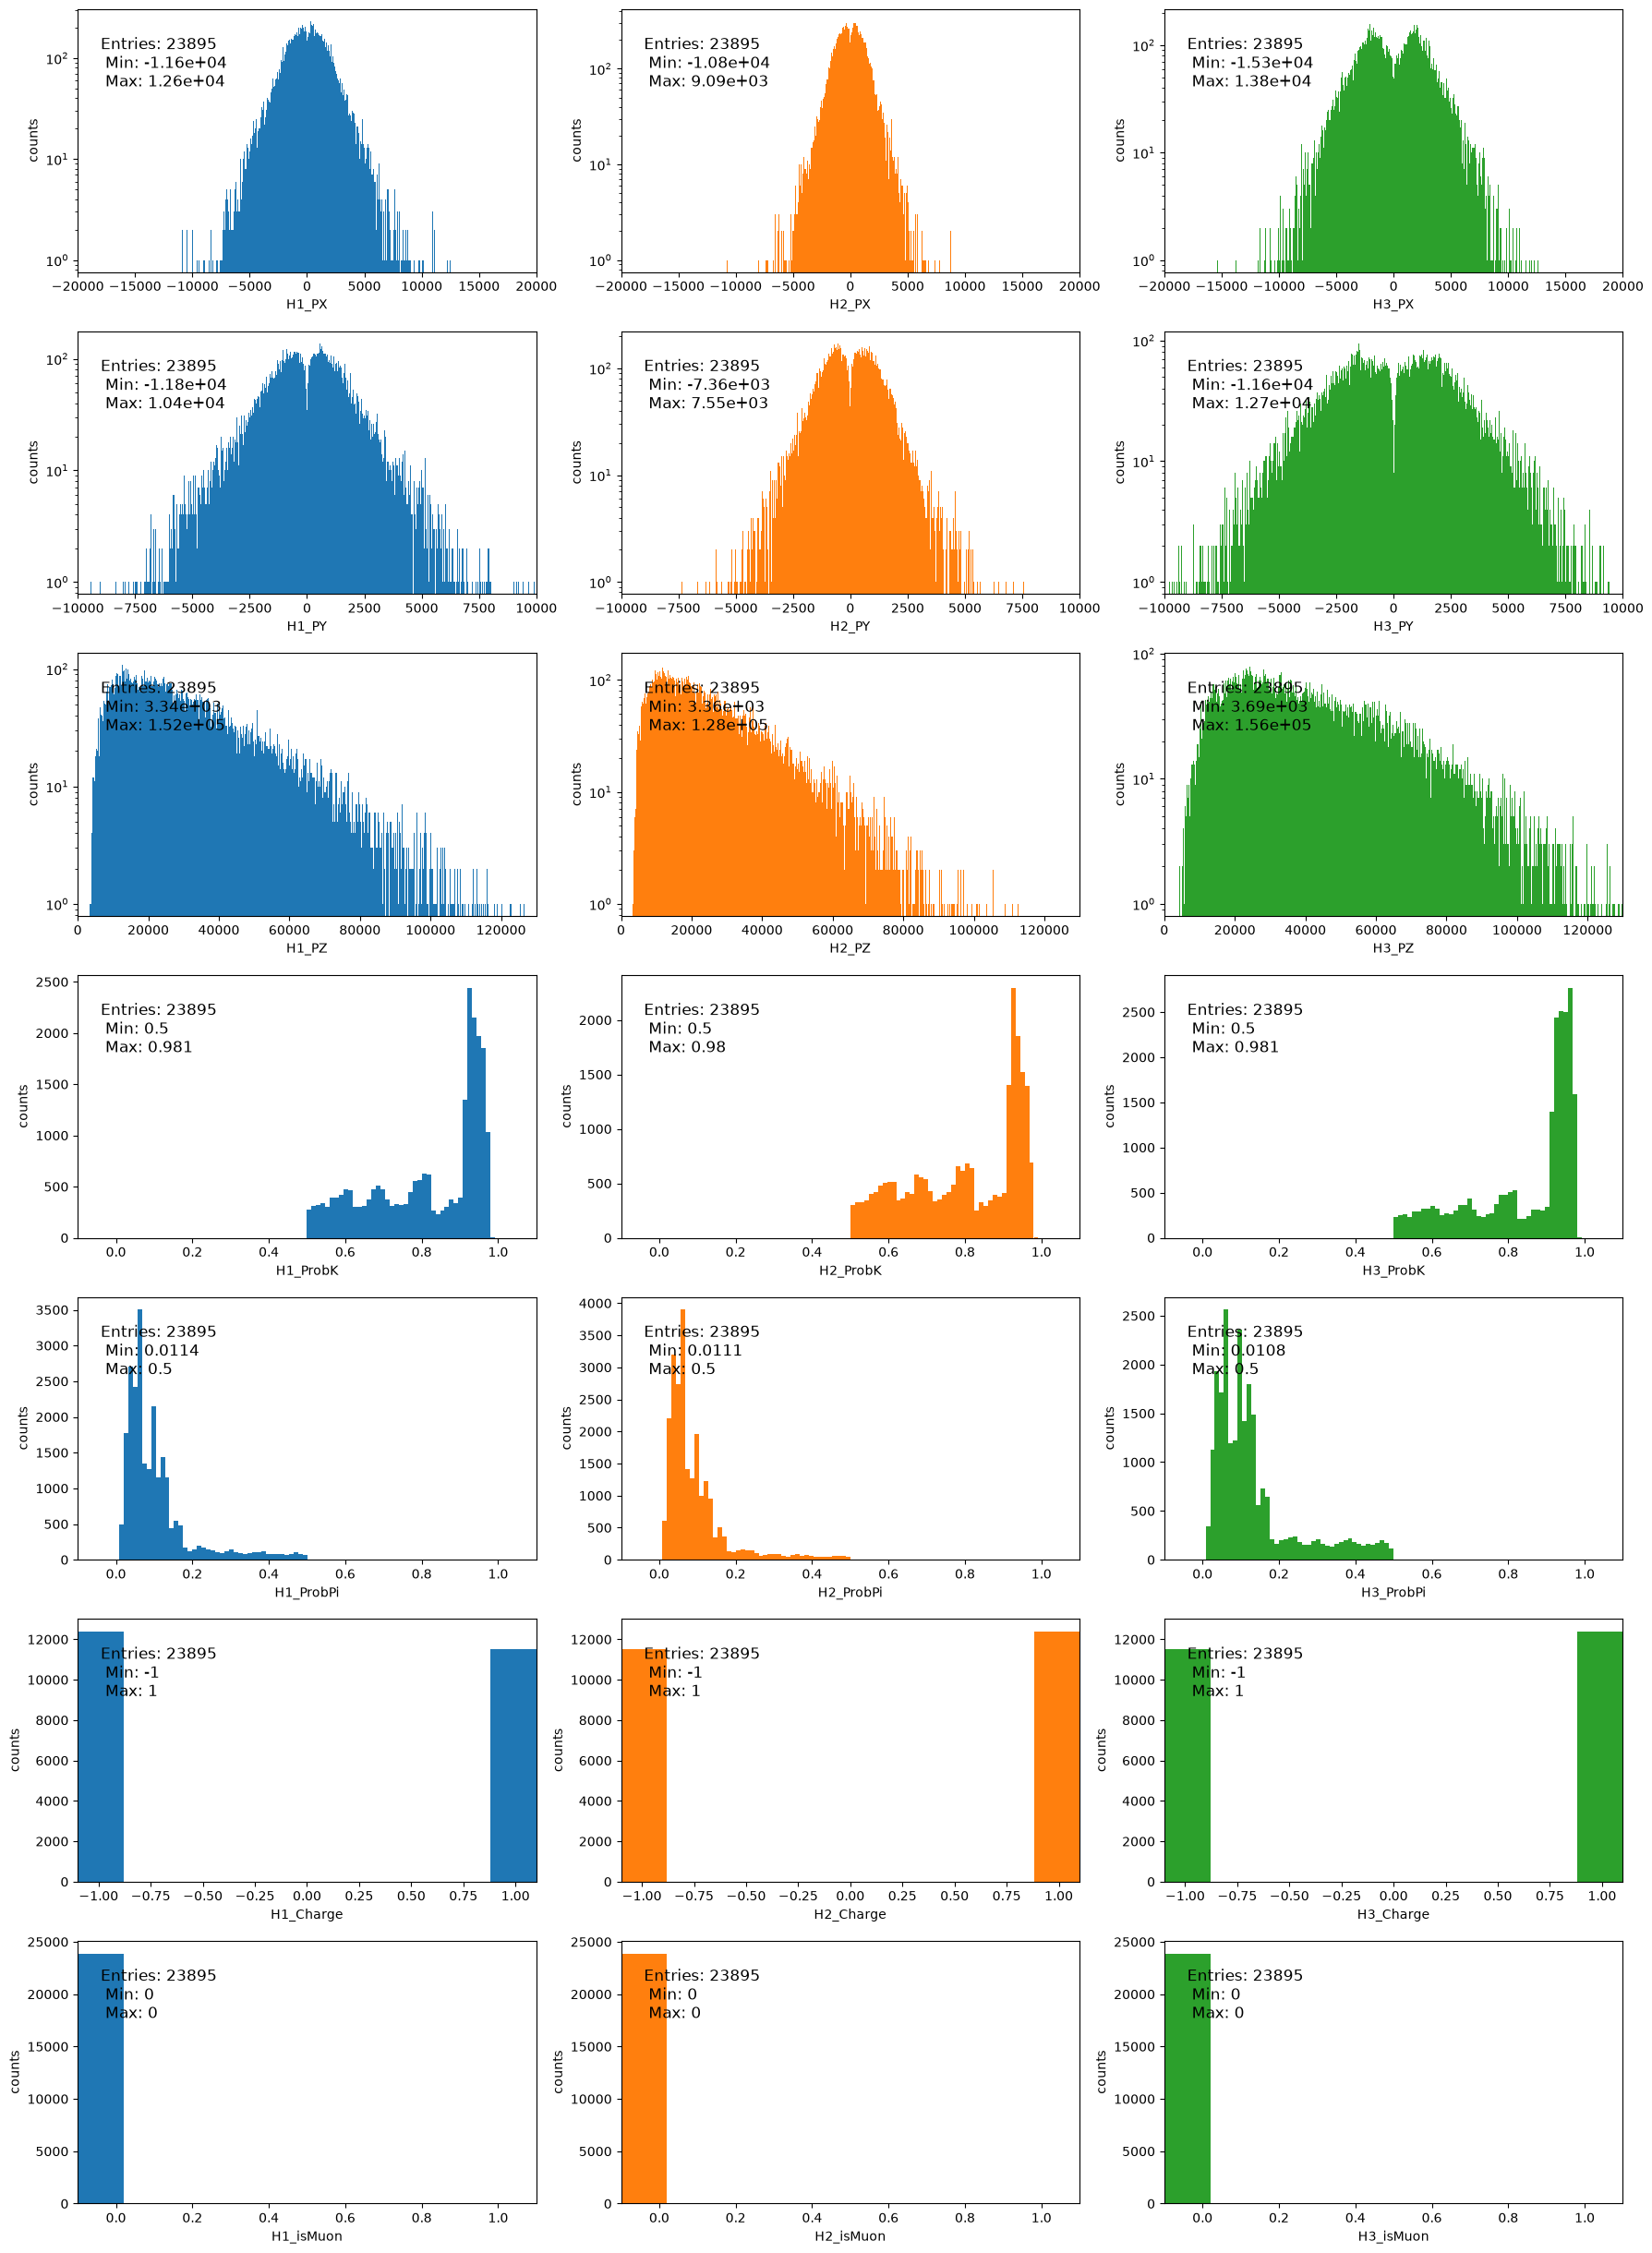

In [12]:
presel_kaon = lf.kaon_preselection(data, cfg)     # boolean mask: 3 kaons, no pions, no muons
print(f"preselection efficiency: {presel_kaon.mean():.2%}")
figs = lf.plot_all_features(data[presel_kaon], product_features=lf.PRODUCT_FEATURES,
                            settings=lf.PLOT_SETTINGS["presel"], n_products=cfg.n_products)

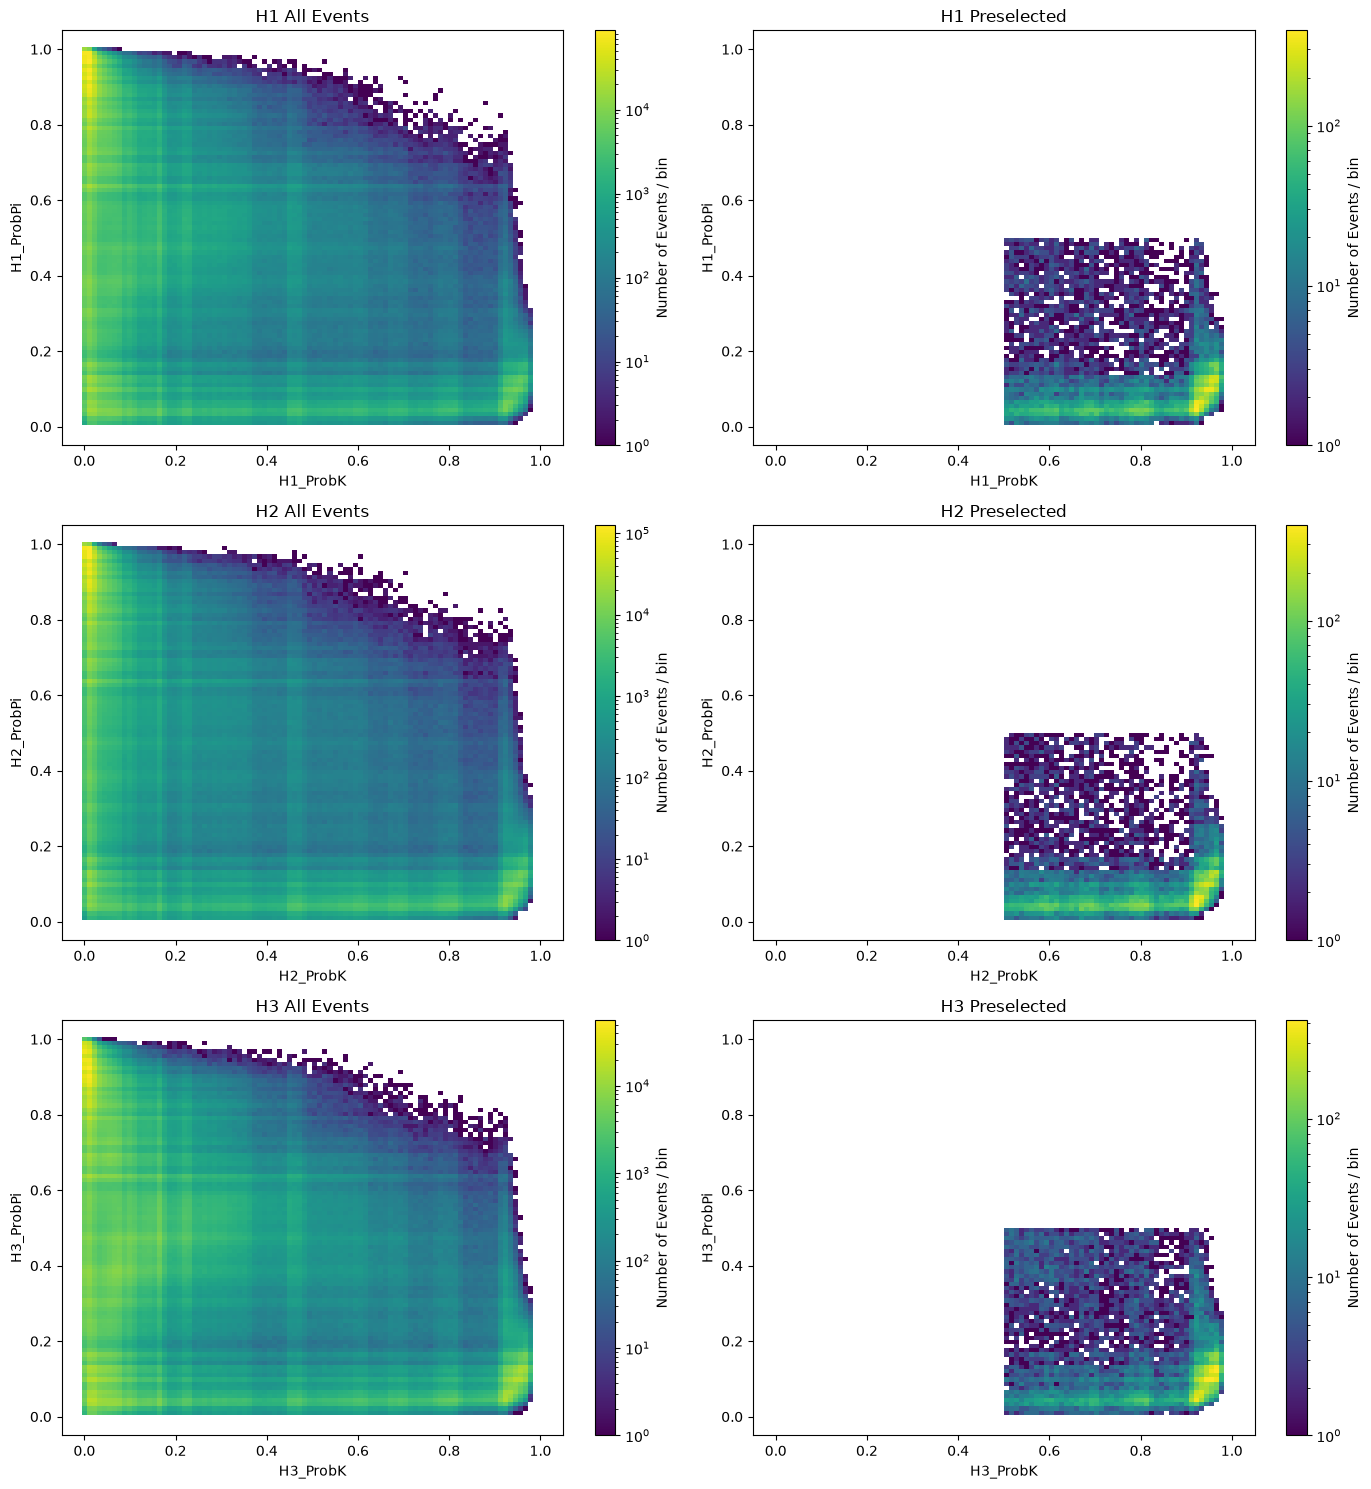

In [13]:
# 2D plot of ProbK vs ProbPi, before / after the preselection
lf.plot_pid_2d(data, data[presel_kaon], cfg);

### Compute Invariant Mass

In [14]:
# [Giacomo, 2026-10-06] sample with PID cuts looser than the whole grid of the preselection scan
# (ProbK > 0.4, ProbPi < 0.6), with B_Mass and B_Charge: used by `scan_preselection_cuts`, which must start from a
# sample not yet preselected with the nominal cuts (0.5), otherwise cuts looser than the nominal ones
# coincide with the nominal selection.
from dataclasses import replace as _replace
data_loose = data[lf.kaon_preselection(data, _replace(cfg, prob_k_min=0.4, prob_pi_max=0.6))].reset_index(drop=True)
lf.add_B_variables(data_loose, cfg)

data = data[presel_kaon].reset_index(drop=True)
lf.add_B_variables(data, cfg)        # B_Mass and B_Charge (= sum of the product charges)
lf.check_charges(data, cfg)          # all charges must be +-1
print(data["B_Charge"].value_counts())

H1_Charge: [-1  1]
H2_Charge: [-1  1]
H3_Charge: [-1  1]
B_Charge
 1    12390
-1    11505
Name: count, dtype: int64


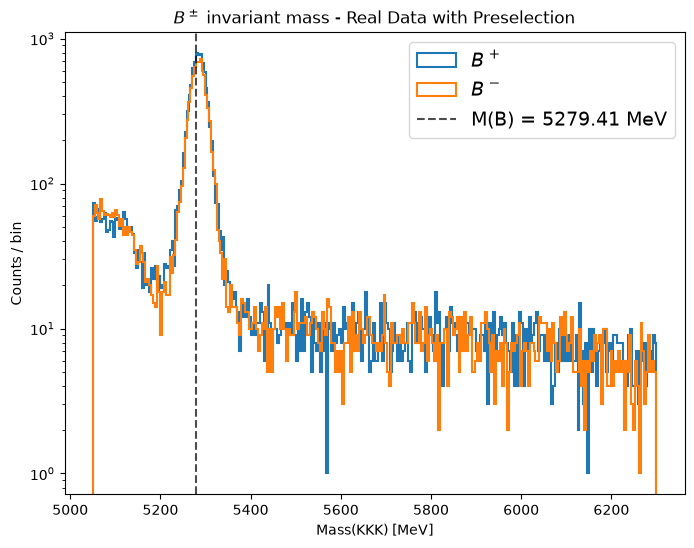

In [15]:
lf.plot_mass_by_charge(data, cfg, bins=300, logy=True, title=r"$B^\pm$ invariant mass - Real Data with Preselection");

events in fit window [5100.0, 5600.0] MeV: 19731
  B+ : 10292   B- : 9439  -->  raw A_CP = -0.043231 ± 0.007112
  magnet down: 11636   magnet up: 8095


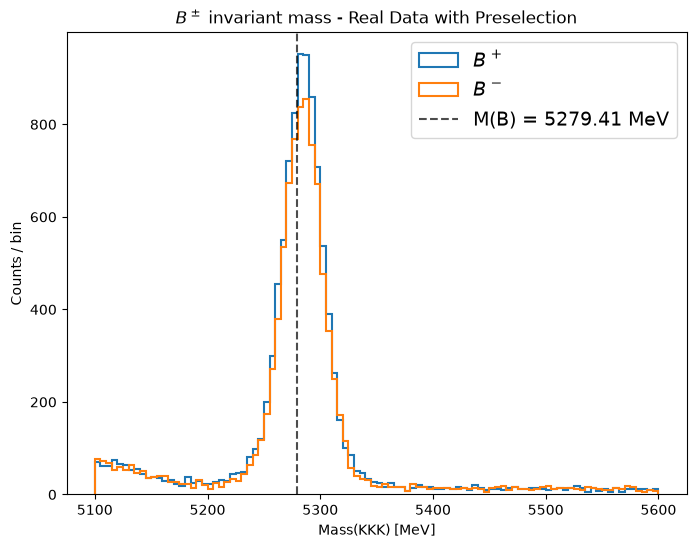

In [16]:
# cut the data in the fit window and split in B+ / B-
data_window = lf.select_window(data, cfg.fit_window)
samples = lf.split_by_charge(data_window, col='B_Mass')       # {'pos': B+ masses, 'neg': B- masses}

lf.plot_mass_by_charge(data_window, cfg, bins=100, bin_range=cfg.fit_window,
                       title=r"$B^\pm$ invariant mass - Real Data with Preselection")
lf.print_event_summary(data_window, cfg)

## Frequentist fit

Conventions (see `lhcb_freq.py`): the model is *extended* (signal yield and background yield are fit parameters),
signal = Gaussian, background = 1 or 2 exponentials (`cfg.n_exp`), both normalised in `cfg.fit_window`.
`A_CP = (N(B-) - N(B+)) / (N(B-) + N(B+))`.

### Sideband

Events in sideband (B+ / B-): 1530 / 1516 | total: 19731


Sideband pos
lam1       -> 0.025433 ± 0.004433
lam2       -> 0.001827 ± 0.000467
f_bkgs     -> 0.276517 ± 0.047763
Sideband neg
lam1       -> 0.024230 ± 0.003569
lam2       -> 0.001090 ± 0.000504
f_bkgs     -> 0.326013 ± 0.043662


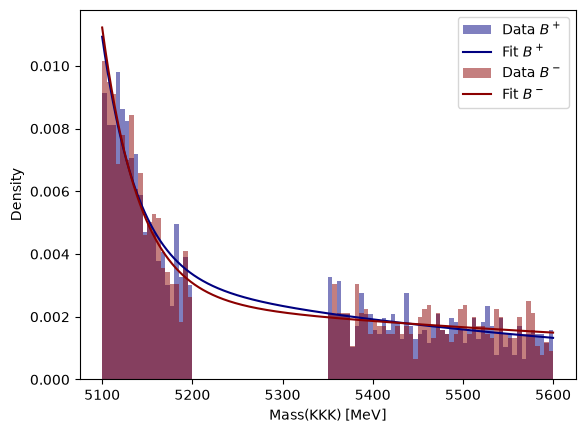

In [17]:
# Sideband = fit window without the signal region
sb_samples = {s: lf.select_sideband(m, cfg) for s, m in samples.items()}
print("Events in sideband (B+ / B-):", len(sb_samples["pos"]), "/", len(sb_samples["neg"]), "| total:", len(data_window))

sb_fits = {s: lf.fit_sideband(m, cfg) for s, m in sb_samples.items()}
for s, f in sb_fits.items():
    print(f"Sideband {s}")
    lf.print_params(f)
lf.plot_sideband(sb_samples, sb_fits, cfg);

In [18]:
# Background expected in the signal region (extrapolated from the sideband) vs observed events
for s, m in samples.items():
    b = lf.expected_background_in_signal(sb_fits[s], len(sb_samples[s]), cfg)
    print(f"{s}: expected background b = {b:.1f},  observed N_obs = {lf.in_region(m, cfg.sig_region).sum()}")

# [Giacomo, 2026-10-07] asymmetry from sideband subtraction: S = N_obs - b in the signal region, for each charge.
# Uncertainty: Poisson on N_obs and, for b (extrapolated from the number of sideband events), b / sqrt(N_sideband);
# the uncertainty on the background shape is neglected.
S, dS = {}, {}
for s, m in samples.items():
    b = lf.expected_background_in_signal(sb_fits[s], len(sb_samples[s]), cfg)
    n_obs = lf.in_region(m, cfg.sig_region).sum()
    S[s] = n_obs - b
    dS[s] = np.sqrt(n_obs + b ** 2 / len(sb_samples[s]))
tot = S["neg"] + S["pos"]
a_sb = (S["neg"] - S["pos"]) / tot
da_sb = 2 * np.sqrt((S["pos"] * dS["neg"]) ** 2 + (S["neg"] * dS["pos"]) ** 2) / tot ** 2
print(f"A_raw (sideband subtraction) = {a_sb:.4f} +- {da_sb:.4f}   (S+ = {S['pos']:.0f}, S- = {S['neg']:.0f})")

pos: expected background b = 544.5,  observed N_obs = 8762
neg: expected background b = 492.2,  observed N_obs = 7923
A_raw (sideband subtraction) = -0.0503 +- 0.0083   (S+ = 8217, S- = 7431)


### Separate fits (B+ and B-)

In [19]:
sep_fits = {s: lf.fit_single(m, cfg) for s, m in samples.items()}
for s, f in sep_fits.items():
    print(s, "valid:", f.valid)
    display(f)
a, da = lf.asymmetry_from_yields(sep_fits)
print(f"A_CP (separate fits) = {a:.4f} ± {da:.4f}")

pos valid: True


┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = -6.536e+04                 │              Nfcn = 262              │
│ EDM = 8.45e-07 (Goal: 0.0002)    │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name   │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ N_sig  │   8.0e3   │   0.1e3   │            │            │    0    │         │       │
│ 1 │ mu     │ 5.28429e3 │ 0.00022e3 │            │            │  5200   │  5350   │       │
│ 2 │ sigma  │   18.0    │    0.2    │            │            │    1    │   100   │       │
│ 3 │ N_bkg  │  2.29e3   │  0.06e3   │            │            │    0    │         │       │
│ 4 │ lam1   │   0.035   │   0.008   │            │            │  1e-06  │    1    │       │
│ 5 │ lam2   │  2.81e-3  │  0.28e-3  │            │            │  1e-06  │    1    │       │
│ 6 │ f_bkgs │   0.113   │   0.028   │            │            │    0    │    1    │       │
└───┴────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌────────┬─────────────────────────────────────────────────────────────────────────────────────┐
│        │       N_sig          mu       sigma       N_bkg        lam1        lam2      f_bkgs │
├────────┼─────────────────────────────────────────────────────────────────────────────────────┤
│  N_sig │    9.19e+03       -0.59        3.65      -1.2e3  -111.99e-3 -5.02221e-3    590.2e-3 │
│     mu │       -0.59       0.049       -0.00        0.59     0.06e-3     5.23e-6     -0.4e-3 │
│  sigma │        3.65       -0.00      0.0388       -3.65    -0.32e-3   -15.10e-6      1.8e-3 │
│  N_bkg │      -1.2e3        0.59       -3.65    3.48e+03   111.99e-3  5.02226e-3   -590.2e-3 │
│   lam1 │  -111.99e-3     0.06e-3    -0.32e-3   111.99e-3    5.84e-05     1.31e-6    -0.16e-3 │
│   lam2 │ -5.02221e-3     5.23e-6   -15.10e-6  5.02226e-3     1.31e-6    8.09e-08    -6.32e-6 │
│ f_bkgs │    590.2e-3     -0.4e-3      1.8e-3   -590.2e-3    -0.16e-3    -6.32e-6    0.000783 │
└────────┴─────────────────────────────────────────────────────────────────────────────────────┘

neg valid: True


┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = -5.799e+04                 │              Nfcn = 226              │
│ EDM = 5.05e-05 (Goal: 0.0002)    │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name   │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ N_sig  │  7.33e3   │  0.09e3   │            │            │    0    │         │       │
│ 1 │ mu     │ 5.28447e3 │ 0.00023e3 │            │            │  5200   │  5350   │       │
│ 2 │ sigma  │   18.0    │    0.2    │            │            │    1    │   100   │       │
│ 3 │ N_bkg  │  2.11e3   │  0.06e3   │            │            │    0    │         │       │
│ 4 │ lam1   │   0.028   │   0.005   │            │            │  1e-06  │    1    │       │
│ 5 │ lam2   │  1.6e-3   │  0.4e-3   │            │            │  1e-06  │    1    │       │
│ 6 │ f_bkgs │   0.21    │   0.04    │            │            │    0    │    1    │       │
└───┴────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌────────┬─────────────────────────────────────────────────────────────────────────────────────┐
│        │       N_sig          mu       sigma       N_bkg        lam1        lam2      f_bkgs │
├────────┼─────────────────────────────────────────────────────────────────────────────────────┤
│  N_sig │    8.46e+03       -0.40        3.59      -1.1e3  -76.319e-3 -9.00933e-3      0.9240 │
│     mu │       -0.40      0.0524       -0.00        0.40   -0.009e-3     4.12e-6     -0.0002 │
│  sigma │        3.59       -0.00      0.0403       -3.59   -0.218e-3   -27.16e-6      0.0028 │
│  N_bkg │      -1.1e3        0.40       -3.59    3.25e+03   76.322e-3  9.00968e-3     -0.9241 │
│   lam1 │  -76.319e-3   -0.009e-3   -0.218e-3   76.322e-3    2.24e-05     1.41e-6   -0.157e-3 │
│   lam2 │ -9.00933e-3     4.12e-6   -27.16e-6  9.00968e-3     1.41e-6    1.68e-07   -14.41e-6 │
│ f_bkgs │      0.9240     -0.0002      0.0028     -0.9241   -0.157e-3   -14.41e-6      0.0016 │
└────────┴─────────────────────────────────────────────────────────────────────────────────────┘

A_CP (separate fits) = -0.0442 ± 0.0087


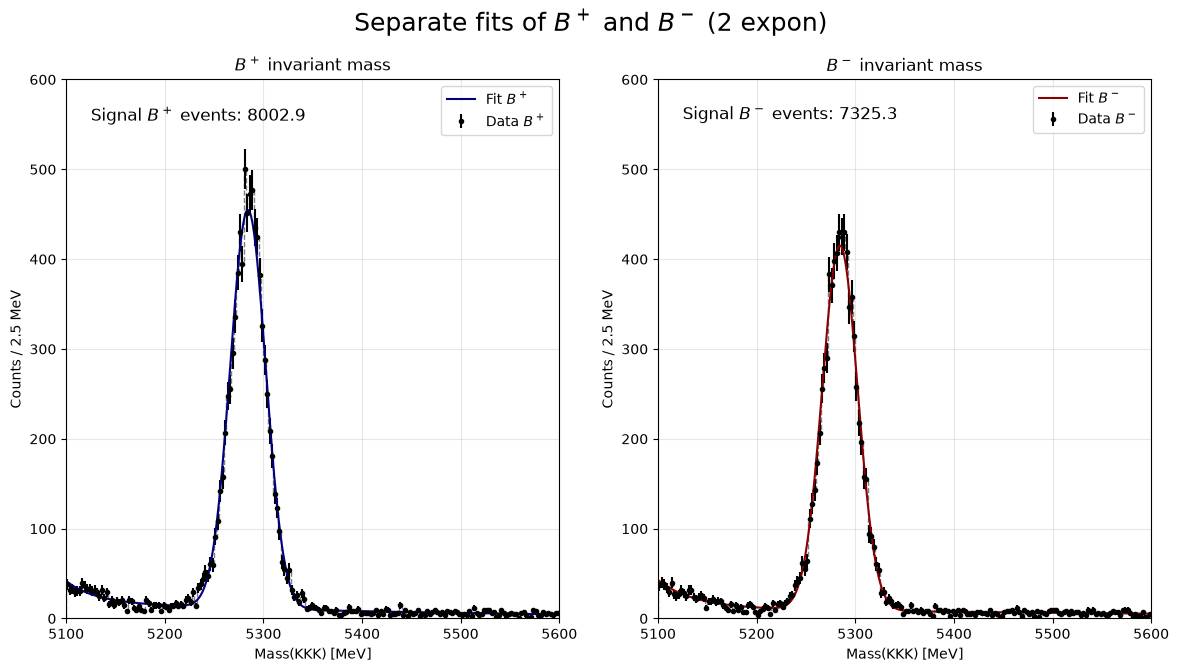

In [20]:
lf.plot_separate_fits(sep_fits, samples, cfg);

#### Goodness of fit ($\chi^2$)

In [21]:
for s, m in samples.items():
    f = sep_fits[s]
    print(f"--- {s}")
    print(lf.chi2_gof(m, lf.fitted_curve(f, cfg), cfg.fit_window, bins=200, n_free=f.nfit))

--- pos
Chi2:         247.66
NDOF:         193
Chi2 / NDOF:  1.283
p-value:      0.0048
--- neg
Chi2:         193.80
NDOF:         193
Chi2 / NDOF:  1.004
p-value:      0.4702


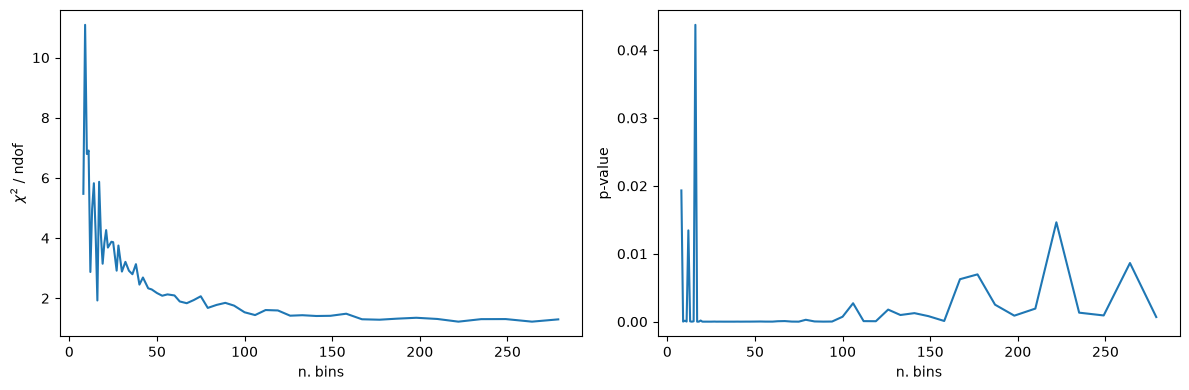

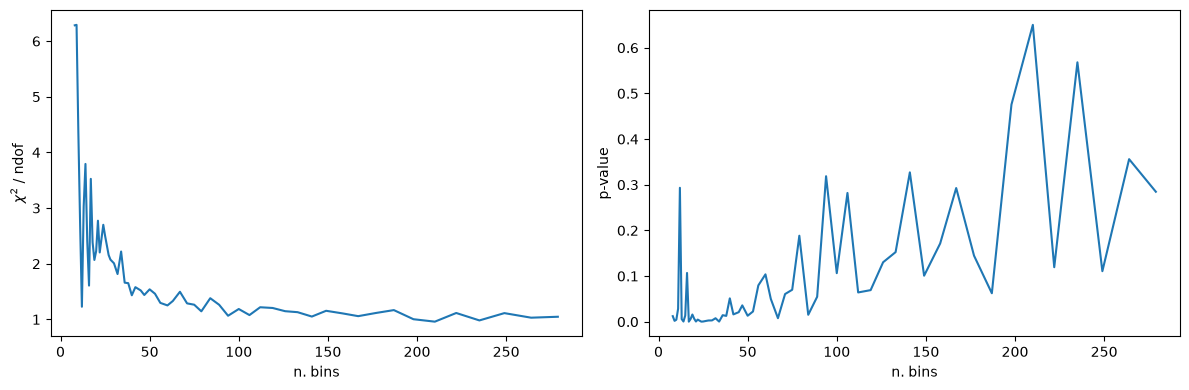

In [22]:
# chi2/ndof and p-value as a function of the number of bins (B+)
bin_values = np.unique(np.logspace(0, 3.5, 100, base=5).astype(int))
f = sep_fits["pos"]
chi2_red, p_vals = lf.scan_gof_bins(samples["pos"], lf.fitted_curve(f, cfg), cfg.fit_window, f.nfit, bin_values)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(bin_values, chi2_red); axes[0].set(xlabel="n. bins", ylabel=r"$\chi^2$ / ndof")
axes[1].plot(bin_values, p_vals);   axes[1].set(xlabel="n. bins", ylabel="p-value")
fig.tight_layout()

# chi2/ndof and p-value as a function of the number of bins (B-)
bin_values = np.unique(np.logspace(0, 3.5, 100, base=5).astype(int))
f = sep_fits["neg"]
chi2_red, p_vals = lf.scan_gof_bins(samples["neg"], lf.fitted_curve(f, cfg), cfg.fit_window, f.nfit, bin_values)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(bin_values, chi2_red); axes[0].set(xlabel="n. bins", ylabel=r"$\chi^2$ / ndof")
axes[1].plot(bin_values, p_vals);   axes[1].set(xlabel="n. bins", ylabel="p-value")
fig.tight_layout()

### Joint Fit

I want to do a joint fit for the B+ and B- peaks. 

The common parameters are:

- mu:    B+/B- mass, the same for both charges (fitted: about 5284.4 MeV)
- sigma: resolution, the same for B+/B- because the detector is symmetric
- N_sig: signal events (B+ and B-)
- A_CP:  CP asymmetry (N_sig_neg - N_sig_pos) / (N_sig_neg + N_sig_pos)

Specific parameters:

- For B+
    - N_bkg_pos:  events of bkgs
    - lam1_pos:   bkg1
    - lam2_pos:   bkg2
    - f_bkgs_pos: fraction of contribution bkg1 respect bkg2

- For B-
    - N_bkg_neg:  events of bkgs
    - lam1_neg:   bkg1
    - lam2_neg:   bkg2
    - f_bkgs_neg: fraction of contribution bkg1 respect bkg2

In [23]:
# 2 exponentials (default) and 1 exponential (simpler background model)
joint = {n: lf.fit_joint(samples, cfg, n_exp=n, minos=True) for n in (2, 1)}
display(joint[1])
display(joint[2])

┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = -1.232e+05                 │              Nfcn = 857              │
│ EDM = 6.33e-06 (Goal: 0.0002)    │            time = 3.6 sec            │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬───────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name      │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼───────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ N_sig     │  15.08e3  │  0.13e3   │  -0.13e3   │   0.13e3   │    0    │         │       │
│ 1 │ A_CP      │  -0.048   │   0.008   │   -0.008   │   0.008    │   -1    │    1    │       │
│ 2 │ mu        │ 5.28449e3 │ 0.00016e3 │ -0.00016e3 │ 0.00016e3  │  5200   │  5350   │       │
│ 3 │ sigma     │   17.64   │   0.13    │   -0.13    │    0.13    │    1    │   100   │       │
│ 4 │ N_bkg_pos │  2.39e3   │  0.06e3   │  -0.06e3   │   0.06e3   │    0    │         │       │
│ 5 │ lam1_pos  │  3.83e-3  │  0.16e-3  │  -0.15e-3  │  0.16e-3   │  1e-06  │    1    │       │
│ 6 │ N_bkg_neg │  2.26e3   │  0.05e3   │  -0.05e3   │   0.05e3   │    0    │         │       │
│ 7 │ lam1_neg  │  3.62e-3  │  0.16e-3  │  -0.16e-3  │  0.16e-3   │  1e-06  │    1    │       │
└───┴───────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌──────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┐
│          │         N_sig         │         A_CP          │          mu           │         sigma         │       N_bkg_pos       │       lam1_pos        │       N_bkg_neg       │       lam1_neg        │
├──────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┤
│  Error   │  -0.13e3  │  0.13e3   │  -0.008   │   0.008   │   -0.16   │   0.16    │   -0.13   │   0.13    │    -60    │    60     │ -0.15e-3  │  0.16e-3  │    -50    │    50     │ -0.16e-3  │  0.16e-3  │
│  Valid   │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │
│ At Limit │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │
│ Max FCN  │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │
│ New Min  │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │
└──────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┘
┌───────────┬──────────────────────────────────────────────────────────────────────────────

┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = -1.234e+05                 │             Nfcn = 3317              │
│ EDM = 3.03e-05 (Goal: 0.0002)    │           time = 18.9 sec            │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬────────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name       │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼────────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ N_sig      │  15.33e3  │  0.13e3   │  -0.13e3   │   0.13e3   │    0    │         │       │
│ 1 │ A_CP       │  -0.044   │   0.008   │   -0.008   │   0.009    │   -1    │    1    │       │
│ 2 │ mu         │ 5.28438e3 │ 0.00016e3 │ -0.00016e3 │ 0.00016e3  │  5200   │  5350   │       │
│ 3 │ sigma      │   18.00   │   0.14    │   -0.14    │    0.14    │    1    │   100   │       │
│ 4 │ N_bkg_pos  │  2.29e3   │  0.06e3   │  -0.06e3   │   0.06e3   │    0    │         │       │
│ 5 │ lam1_pos   │   0.035   │   0.008   │   -0.007   │   0.008    │  1e-06  │    1    │       │
│ 6 │ lam2_pos   │  2.81e-3  │  0.28e-3  │  -0.29e-3  │  0.26e-3   │  1e-06  │    1    │       │
│ 7 │ f_bkgs_pos │   0.112   │   0.028   │   -0.024   │   0.030    │    0    │    1    │       │
│ 8 │ N_bkg_neg  │  2.11e3   │  0.06e3   │  -0.06e3   │   0.06e3   │    0    │         │       │
│ 9 │ lam1_neg   │   0.028   │   0.005   │   -0.004   │   0.005    │  1e-06  │    1    │       │
│ 10│ lam2_neg   │  1.6e-3   │  0.4e-3   │  -0.4e-3   │   0.4e-3   │  1e-06  │    1    │       │
│ 11│ f_bkgs_neg │   0.210   │   0.039   │   -0.035   │   0.040    │    0    │    1    │       │
└───┴────────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌──────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┐
│          │         N_sig         │         A_CP          │          mu           │         sigma         │       N_bkg_pos       │       lam1_pos        │       lam2_pos        │      f_bkgs_pos       │       N_bkg_neg       │       lam1_neg        │       lam2_neg        │      f_bkgs_neg       │
├──────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┤
│  Error   │  -0.13e3  │  0.13e3   │  -0.008   │   0.009   │   -0.16   │   0.16    │   -0.14   │   0.14    │    -60    │    60     │  -0.007   │   0.008   │ -0.29e-3  │  0.26e-3  │  -0.024   │   0.030   │    -60    │    60     │  -0.004   │   0.005   │  -0.4e-3  │  0.4e-3   │  -0.035   │   0.040   │
│  Valid   │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │
│ At Limit │   False   │   Fals


=== 2 exponential(s) ===  valid: True
A_CP = -0.0441 ± 0.0085   (relative error 19.3%, Hesse significance 5.19 sigma)
Chi2:         441.72
NDOF:         388
Chi2 / NDOF:  1.138
p-value:      0.0308

=== 1 exponential(s) ===  valid: True
A_CP = -0.0481 ± 0.0085   (relative error 17.6%, Hesse significance 5.67 sigma)
Chi2:         576.26
NDOF:         392
Chi2 / NDOF:  1.470
p-value:      0.0000


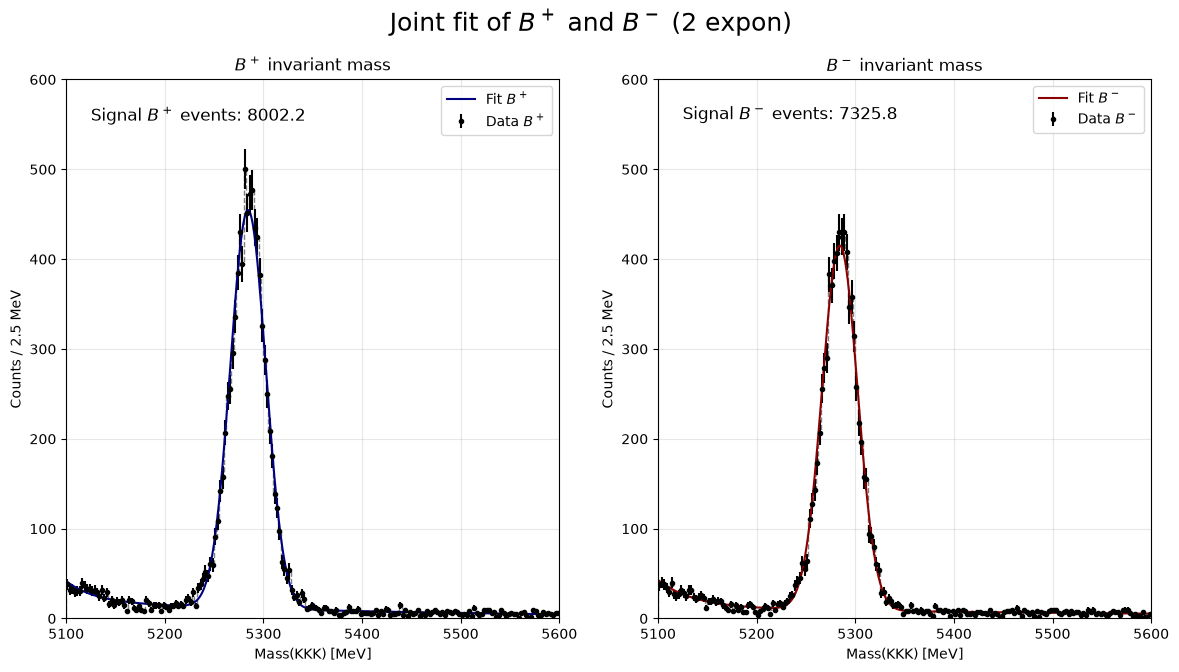

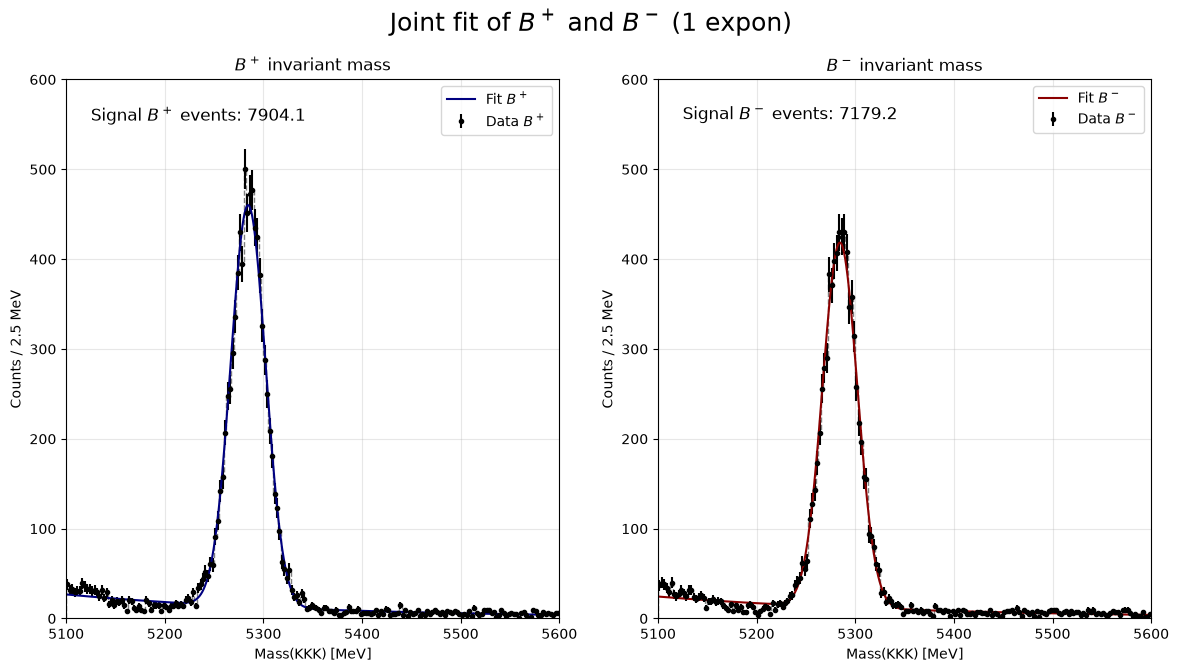

In [24]:
for n, m in joint.items():
    print(f"\n=== {n} exponential(s) ===  valid: {m.valid}")
    lf.print_asymmetry(m)
    print(lf.gof_joint(m, samples, cfg, n_exp=n))
    lf.plot_joint_fit(m, samples, cfg, n_exp=n)

### Profiled Likelihood and hypothesis test

In [25]:
best = joint[2]
POIS = ["A_CP", "mu"]                                        # parameters of interest
nuisance = [p for p in best.parameters if p not in POIS]     # everything else is profiled

t, p, _ = lf.wilks_test(best, {"A_CP": 0.0})                 # H0: no CP violation
# [Giacomo, 2026-10-07] significance Z = sqrt(t) (likelihood ratio, one parameter), as in the report
print(f"H0: A_CP = 0  ->  t = {t:.2f},  p-value = {p:.2e}  (Z = sqrt(t) = {np.sqrt(t):.2f} sigma)")

H0: A_CP = 0  ->  t = 26.99,  p-value = 2.05e-07  (Z = sqrt(t) = 5.20 sigma)


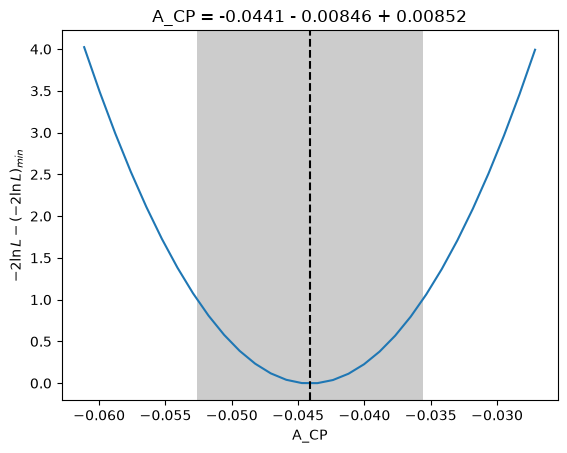

In [26]:
best.draw_mnprofile("A_CP")
plt.ylabel(r"$-2\ln L - (-2\ln L)_{min}$");

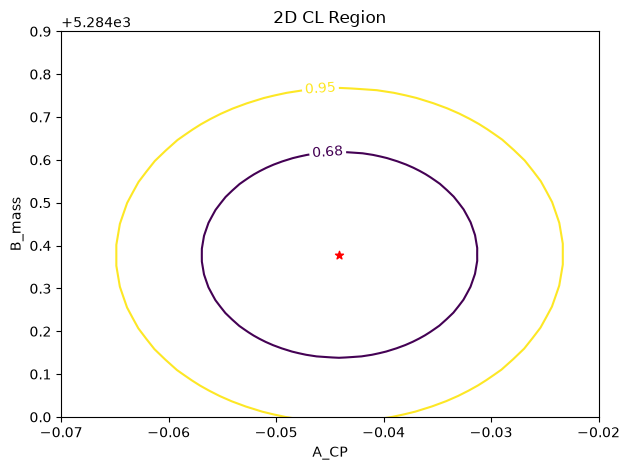

In [27]:
best.draw_mncontour("A_CP", "mu", cl=[0.68, 0.95])
plt.scatter([best.values["A_CP"]], [best.values["mu"]], marker="*", color="r")
plt.title("2D CL Region")
plt.xlabel("A_CP")
plt.ylabel("B_mass")
plt.xlim(-0.07, -0.020)
plt.ylim(5284.0, 5284.9)
plt.tight_layout()

### Coverage check (bootstrap) of Wilks' theorem

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 1/1000 [00:04<1:19:43,  4.79s/it]

  0%|          | 2/1000 [00:08<1:13:40,  4.43s/it]

  0%|          | 3/1000 [00:13<1:11:30,  4.30s/it]

  0%|          | 4/1000 [00:15<1:00:40,  3.65s/it]

...

100%|█████████▉| 998/1000 [48:34<00:06,  3.07s/it]

100%|█████████▉| 999/1000 [48:38<00:03,  3.42s/it]

100%|██████████| 1000/1000 [48:40<00:00,  3.07s/it]

100%|██████████| 1000/1000 [48:40<00:00,  2.92s/it]

coverage of the 1.00 (68.3%) threshold: 68.4% +- 1.5%   (1000 toys, 0 failed)


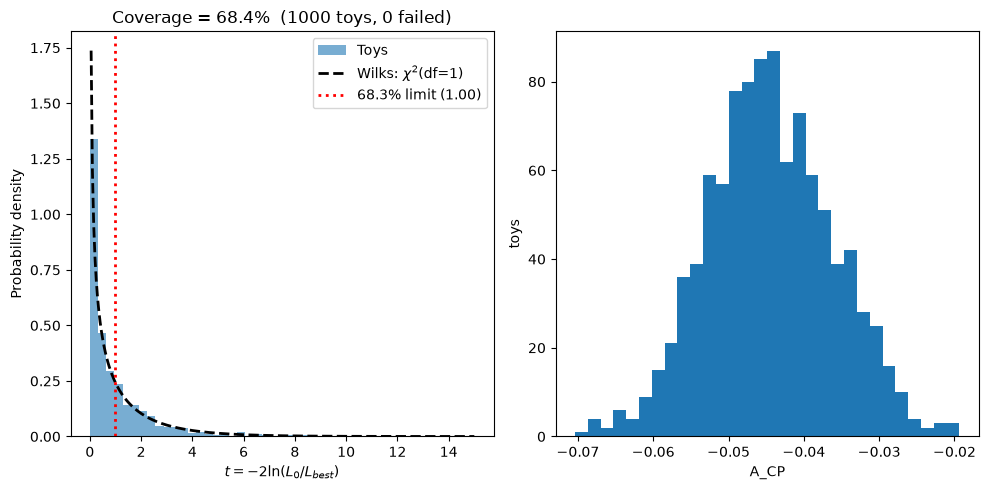

In [28]:
# [Giacomo, 2026-10-07] coverage of the Wilks interval on A_CP alone (mu and all other parameters profiled,
# chi2_1 threshold at 68.3% = 0.99), with the nominal window: directly comparable with the 68% Bayesian credible
# interval on A. (Before: (A_CP, mu) plane, threshold 2.30, old window [5100, 6000] -> 67.2%.)
res = lf.run_coverage_study(data_window, cfg, best, pois=["A_CP"], n_toys=1000, seed=1)
p_cov = res.coverage; dp_cov = np.sqrt(p_cov * (1 - p_cov) / len(res.t_values))
print(f"coverage of the {res.t_crit:.2f} (68.3%) threshold: {p_cov:.1%} +- {dp_cov:.1%}   ({len(res.t_values)} toys, {res.n_failed} failed)")
lf.plot_coverage(res);

### Systematic Uncertanties

1. Change the fit_window limits

In [29]:
# fit_window_limits = {
#     'left':  [5000, 5025, 5050, 5075, 5100, 5125, 5150, 5175, 5200],
#     'right': [5350, 5375, 5400, 5425, 5450, 5475, 5500, 5525, 5550, 5575, 5600, 5625, 5650, 5675, 5700, 5725, 5750, 5775, 5800, 5825, 5850, 5875, 5900, 5925, 5950, 5975, 6000, 6025, 6050, 6075, 6100]
# }

fit_window_limits = {
    'left':  [5000, 5050, 5100, 5150, 5200],
    'right': [5350, 5400, 5450, 5500, 5550, 5600, 5650, 5700, 5750, 5800, 5850, 5900, 5950, 6000, 6050, 6100]
}

In [30]:
res_win = lf.scan_fit_window(data, cfg, fit_window_limits["left"], fit_window_limits["right"])
ok_win = res_win[res_win.valid & res_win.accurate]

scan:   0%|          | 0/80 [00:00<?, ?it/s]

scan:   1%|▏         | 1/80 [00:03<04:26,  3.37s/it]

scan:   2%|▎         | 2/80 [00:06<04:09,  3.20s/it]

scan:   4%|▍         | 3/80 [00:10<04:51,  3.79s/it]

scan:   5%|▌         | 4/80 [00:12<03:43,  2.94s/it]

...

scan:  96%|█████████▋| 77/80 [04:47<00:16,  5.44s/it]

scan:  98%|█████████▊| 78/80 [04:51<00:10,  5.05s/it]

scan:  99%|█████████▉| 79/80 [04:58<00:05,  5.46s/it]

scan: 100%|██████████| 80/80 [05:03<00:00,  5.36s/it]

scan: 100%|██████████| 80/80 [05:03<00:00,  3.79s/it]

nominal A_CP = -0.04413 ± 0.00850 (stat)
mean A_CP    = -0.04516 ± 0.00175 (syst)
std over windows        = 0.00177
mean err over windows   = 0.00852
max |A_CP - nominal|    = 0.00482


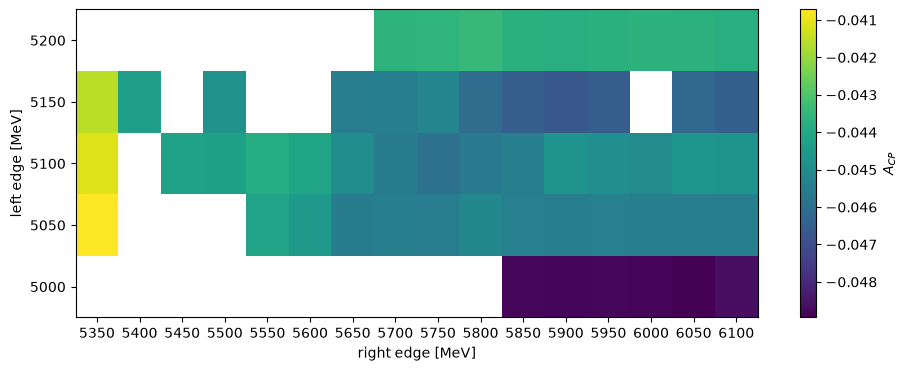

In [31]:
# [Giacomo, 2026-10-06] note: all windows of the grid contain the nominal one, so the results are correlated and
# part of the spread is statistical (Barlow criterion: compare the shift with sqrt(|sigma_var^2 - sigma_nom^2|)).
# This scan is a stability check; the systematic uncertainty is the common study of Frequentist_Systematics.ipynb.
# The same holds for the scan of the cuts.
nominal_win = ok_win[(ok_win.left == cfg.fit_window[0]) & (ok_win.right == cfg.fit_window[1])].iloc[0]

pivot_win = ok_win.pivot(index="left", columns="right", values="A_CP")
fig, ax = plt.subplots(figsize=(11, 4))
im = ax.pcolormesh(pivot_win.columns, pivot_win.index, pivot_win.values, shading="nearest")
fig.colorbar(im, label=r"$A_{CP}$")
ax.set(xlabel="right edge [MeV]", ylabel="left edge [MeV]")
ax.set_xticks(pivot_win.columns)
ax.set_yticks(pivot_win.index)

print(f"nominal A_CP = {nominal_win.A_CP:.5f} ± {nominal_win.A_CP_err:.5f} (stat)")
print(f"mean A_CP    = {np.mean(ok_win['A_CP']):.5f} ± {np.std(ok_win['A_CP']):.5f} (syst)")
print(f"std over windows        = {ok_win.A_CP.std():.5f}")
print(f"mean err over windows   = {np.mean(ok_win.A_CP_err):.5f}")
print(f"max |A_CP - nominal|    = {(ok_win.A_CP - nominal_win.A_CP).abs().max():.5f}")

2. Change the sig_region limits

In [32]:
sig_region_limits = {
    'left':  [5150, 5170, 5185, 5200, 5215, 5230, 5250],
    'right': [5320, 5335, 5350, 5365, 5380, 5400, 5420]
}

In [33]:
# [Giacomo, 2026-10-06] note: in the joint fit the signal region enters only the starting values (sideband fits)
# and the limit on mu, so A does not depend on it (spread 2e-5): a stability check of the fit, not a systematic.
res_sr  = lf.scan_signal_region(data, cfg, sig_region_limits['left'], sig_region_limits['right'])
ok_sr = res_sr[res_sr.valid & res_sr.accurate]

scan:   0%|          | 0/49 [00:00<?, ?it/s]

scan:   2%|▏         | 1/49 [00:10<08:20, 10.43s/it]

scan:   4%|▍         | 2/49 [00:16<06:02,  7.72s/it]

scan:   6%|▌         | 3/49 [00:19<04:13,  5.51s/it]

scan:   8%|▊         | 4/49 [00:22<03:25,  4.56s/it]

...

scan:  94%|█████████▍| 46/49 [03:04<00:18,  6.14s/it]

scan:  96%|█████████▌| 47/49 [03:13<00:13,  6.89s/it]

scan:  98%|█████████▊| 48/49 [03:18<00:06,  6.41s/it]

scan: 100%|██████████| 49/49 [03:24<00:00,  6.21s/it]

scan: 100%|██████████| 49/49 [03:24<00:00,  4.17s/it]

nominal A_CP = -0.04413 ± 0.00850 (stat)
mean A_CP    = -0.04411 ± 0.00002 (syst)
std over windows        = 0.00002
mean err over windows   = 0.00850
max |A_CP - nominal|    = 0.00006


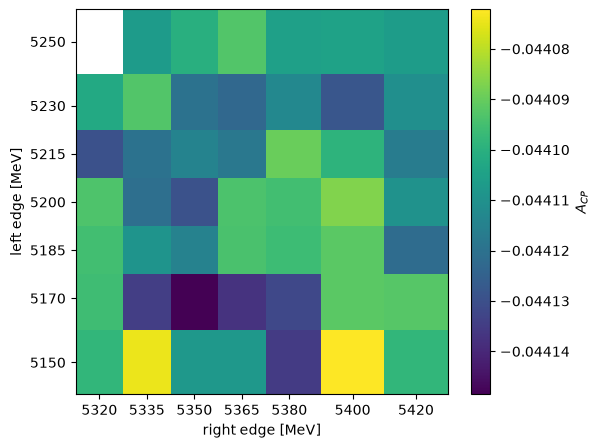

In [34]:
nominal_sr = ok_sr[(ok_sr.sig_lo == cfg.sig_region[0]) & (ok_sr.sig_hi == cfg.sig_region[1])].iloc[0]

pivot_sr = ok_sr.pivot(index="sig_lo", columns="sig_hi", values="A_CP")
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.pcolormesh(pivot_sr.columns, pivot_sr.index, pivot_sr.values, shading="nearest")
fig.colorbar(im, label=r"$A_{CP}$")
ax.set(xlabel="right edge [MeV]", ylabel="left edge [MeV]")
ax.set_xticks(pivot_sr.columns)
ax.set_yticks(pivot_sr.index)

print(f"nominal A_CP = {nominal_sr.A_CP:.5f} ± {nominal_sr.A_CP_err:.5f} (stat)")
print(f"mean A_CP    = {np.mean(ok_sr['A_CP']):.5f} ± {np.std(ok_sr['A_CP']):.5f} (syst)")
print(f"std over windows        = {ok_sr.A_CP.std():.5f}")
print(f"mean err over windows   = {np.mean(ok_sr.A_CP_err):.5f}")
print(f"max |A_CP - nominal|    = {(ok_sr.A_CP - nominal_sr.A_CP).abs().max():.5f}")

3. Selection

In [35]:
scan_cuts = {
    "prob_k_min":   [0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8],
    "prob_pi_max":  [0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6],
}

scan_cuts = {
    "prob_k_min":   np.arange(0.45, 0.81, 0.025),
    "prob_pi_max":  np.arange(0.30, 0.56, 0.025),
}

In [36]:
# [Giacomo, 2026-10-06] `data_loose` (see above) instead of `data`, already preselected with the nominal cuts
res_cuts  = lf.scan_preselection_cuts(data_loose, cfg, scan_cuts['prob_k_min'], scan_cuts['prob_pi_max'])
ok_cuts = res_cuts[res_cuts.valid & res_cuts.accurate]

scan:   0%|          | 0/165 [00:00<?, ?it/s]

scan:   1%|          | 1/165 [00:02<06:33,  2.40s/it]

scan:   1%|          | 2/165 [00:05<06:51,  2.52s/it]

scan:   2%|▏         | 3/165 [00:07<06:51,  2.54s/it]

scan:   2%|▏         | 4/165 [00:10<06:53,  2.57s/it]

...

scan:  98%|█████████▊| 162/165 [04:31<00:02,  1.41it/s]

scan:  99%|█████████▉| 163/165 [04:32<00:01,  1.40it/s]

scan:  99%|█████████▉| 164/165 [04:33<00:00,  1.32it/s]

scan: 100%|██████████| 165/165 [04:34<00:00,  1.32it/s]

scan: 100%|██████████| 165/165 [04:34<00:00,  1.66s/it]

nominal A_CP = -0.04413        ±   0.00850 (stat)
mean A_CP    = -0.04381 ± 0.00455 (syst)
std over windows        = 0.00457
mean err over windows   = 0.01121
max |A_CP - nominal|    = 0.01263


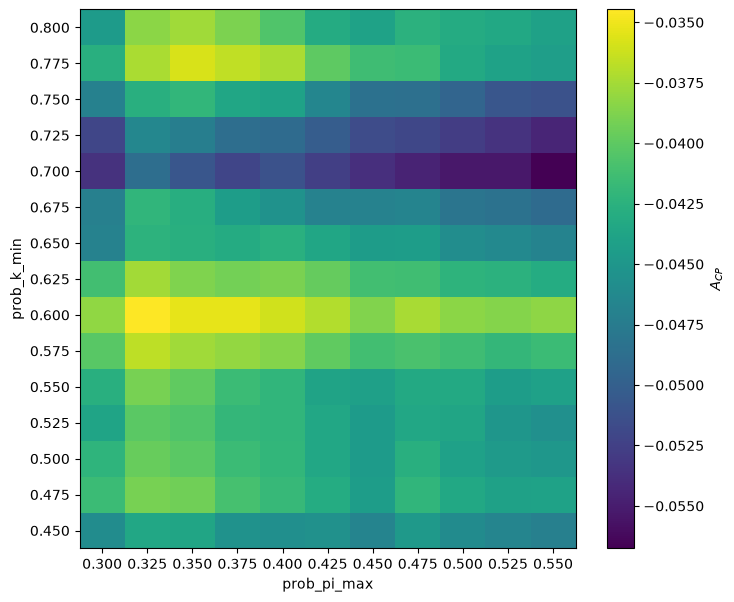

In [37]:
nominal_cuts = ok_cuts[(abs(ok_cuts.prob_k_min-cfg.prob_k_min) < 0.01) & (abs(ok_cuts.prob_pi_max-cfg.prob_pi_max) < 0.01)].iloc[0]

pivot_cuts = ok_cuts.pivot(index="prob_k_min", columns="prob_pi_max", values="A_CP")
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.pcolormesh(pivot_cuts.columns, pivot_cuts.index, pivot_cuts.values, shading="nearest")
fig.colorbar(im, label=r"$A_{CP}$")
ax.set(xlabel="prob_pi_max", ylabel="prob_k_min")
ax.set_xticks(pivot_cuts.columns)
ax.set_yticks(pivot_cuts.index)

print(f"nominal A_CP = {nominal_cuts.A_CP:.5f}        ±   {nominal_cuts.A_CP_err:.5f} (stat)")
print(f"mean A_CP    = {np.mean(ok_cuts['A_CP']):.5f} ± {np.std(ok_cuts['A_CP']):.5f} (syst)")
print(f"std over windows        = {ok_cuts.A_CP.std():.5f}")
print(f"mean err over windows   = {np.mean(ok_cuts.A_CP_err):.5f}")
print(f"max |A_CP - nominal|    = {(ok_cuts.A_CP - nominal_cuts.A_CP).abs().max():.5f}")

# Dalitz plots
## Aims:
* Produce Dalitz plots of the simulation and real data sample
* Create ordered and binned dalitz plots.
* Identify two body resonances in the Dalitz plots

In this stage we introduce you to an important technique for analysing decays of one particle (your charged B meson) into three bodies (the three kaons). This is known as a Dalitz plot. 

The decay of the B meson can proceed either directly to the three-body final state or via an intermediate particle. For example, B<sup>+</sup> → K<sup>+</sup>K<sup>+</sup>K<sup>−</sup>, could proceed through the decay  B<sup>+</sup> → K<sup>+</sup>R<sup>0</sup>, where R<sup>0</sup> is a neutral particle resonance which can decay R<sup>0</sup> → K<sup>+</sup>K<sup>-</sup>. Dalitz plots can be used to identify these resonances which are visible as bands on the Dalitz plot.

More information about these plots and why these are used in particle physics research can be found in [Dalitz Plot Introduction](Background-Information-Notebooks/DalitzPlots.ipynb).

The kinematics of a three-body decay can be fully described using only two variables. The energies and momenta of the three kaons are not independent of each other as they all come from the decay of a B meson and energy and momentum are conserved. The axes of the plots conventionally are the squared invariant masses of two pairs of the decay products. It is a 2D plot, the x and y axes are both squared masses and the density of points in the plot shows the structure.

Consider our decay B<sup>+</sup> → K<sup>+</sup><sub>1</sub>K<sup>+</sup><sub>2</sub>K<sup>−</sup><sub>3</sub>, where we have numbered the kaons 1,2,3 to distinguish them. We can calculate the invariant mass of three possible combinations that could correspond to intermediate resonances R<sup>++</sup><sub>1</sub> → K<sup>+</sup><sub>1</sub>K<sup>+</sup><sub>2</sub>, R<sup>0</sup><sub>2</sub> → K<sup>+</sup><sub>1</sub>K<sup>-</sup><sub>3</sub>, and R<sup>0</sup><sub>3</sub> → K<sup>+</sup><sub>3</sub>K<sup>-</sup><sub>3</sub>. 

The potential R<sup>++</sup><sub>1</sub> would be a doubly charged resonance. We would not expect to see any resonances corresponding to this as mesons are composed of one quark and one anti-quark and their charges cannot add up to two units.

The potential R<sup>0</sup><sub>2</sub> and R<sup>0</sup><sub>3</sub> correspond to configurations in which we could see resonances. Hence you should compute the invariant mass combinations for these. The square of these masses should be used as the Dalitz variables. 

We suggest you make these plots first for the simulation data. In the simulation there are no intermediate resonances and your plot should be of uniform density inside the range physically allowed by energy and momentum conservation.
	

### Simulation Data

In [38]:
# For Simulation Data the charges are mixed
df_sim[['H1_Charge', 'H2_Charge', 'H3_Charge', 'B_Charge']][:5]

,H1_Charge,H2_Charge,H3_Charge,B_Charge
0,-1,1,-1,-1
1,1,-1,-1,-1
2,-1,1,1,1
3,1,-1,1,1
4,-1,1,-1,-1


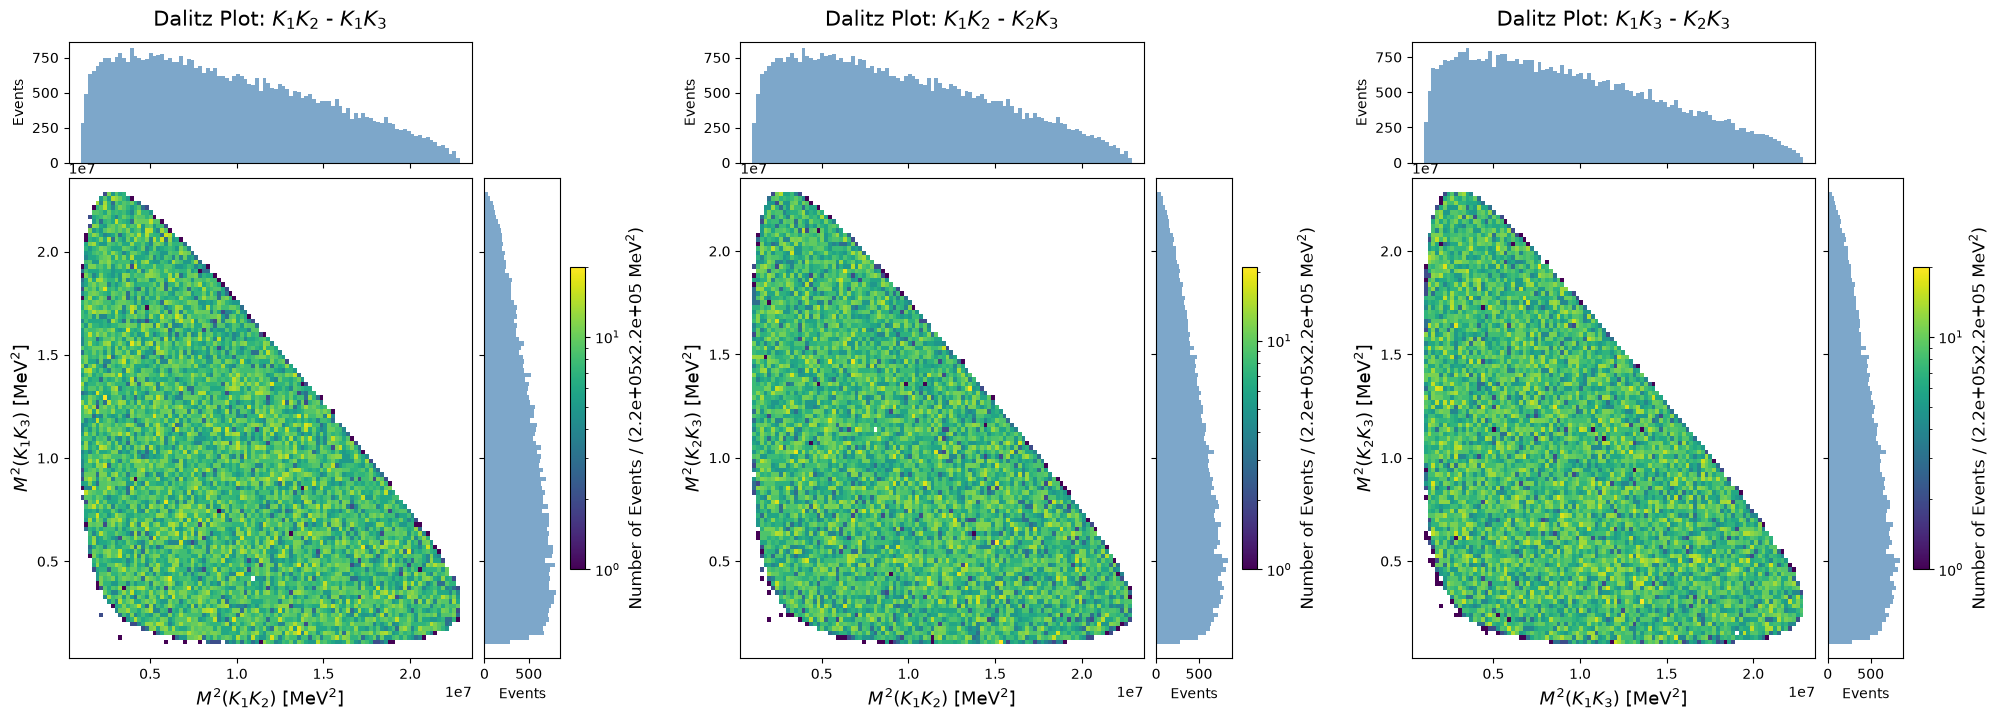

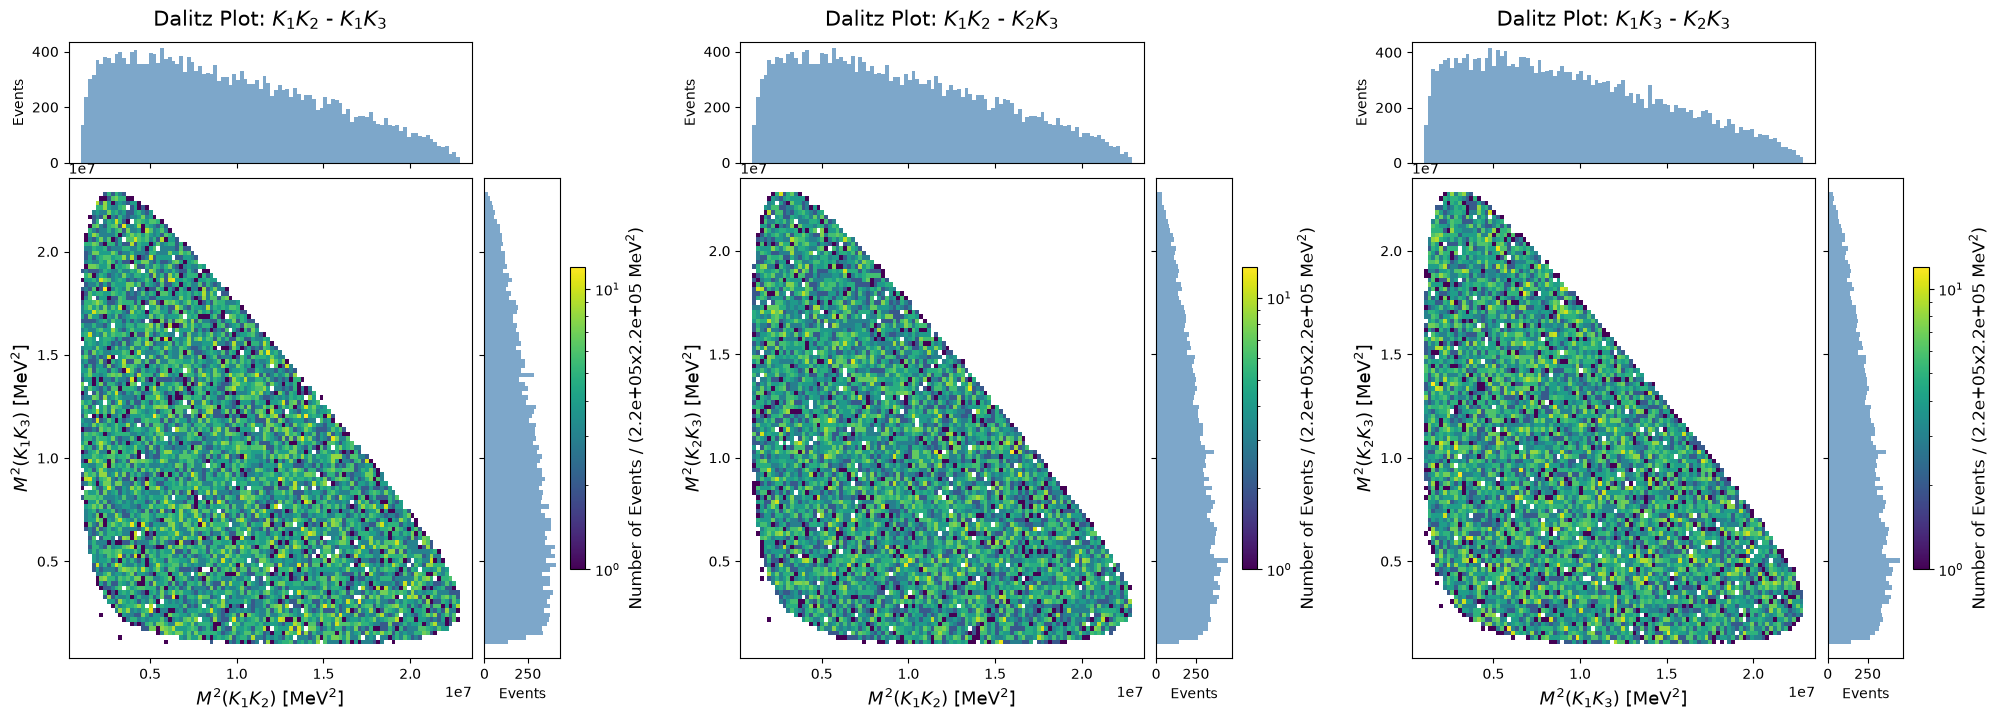

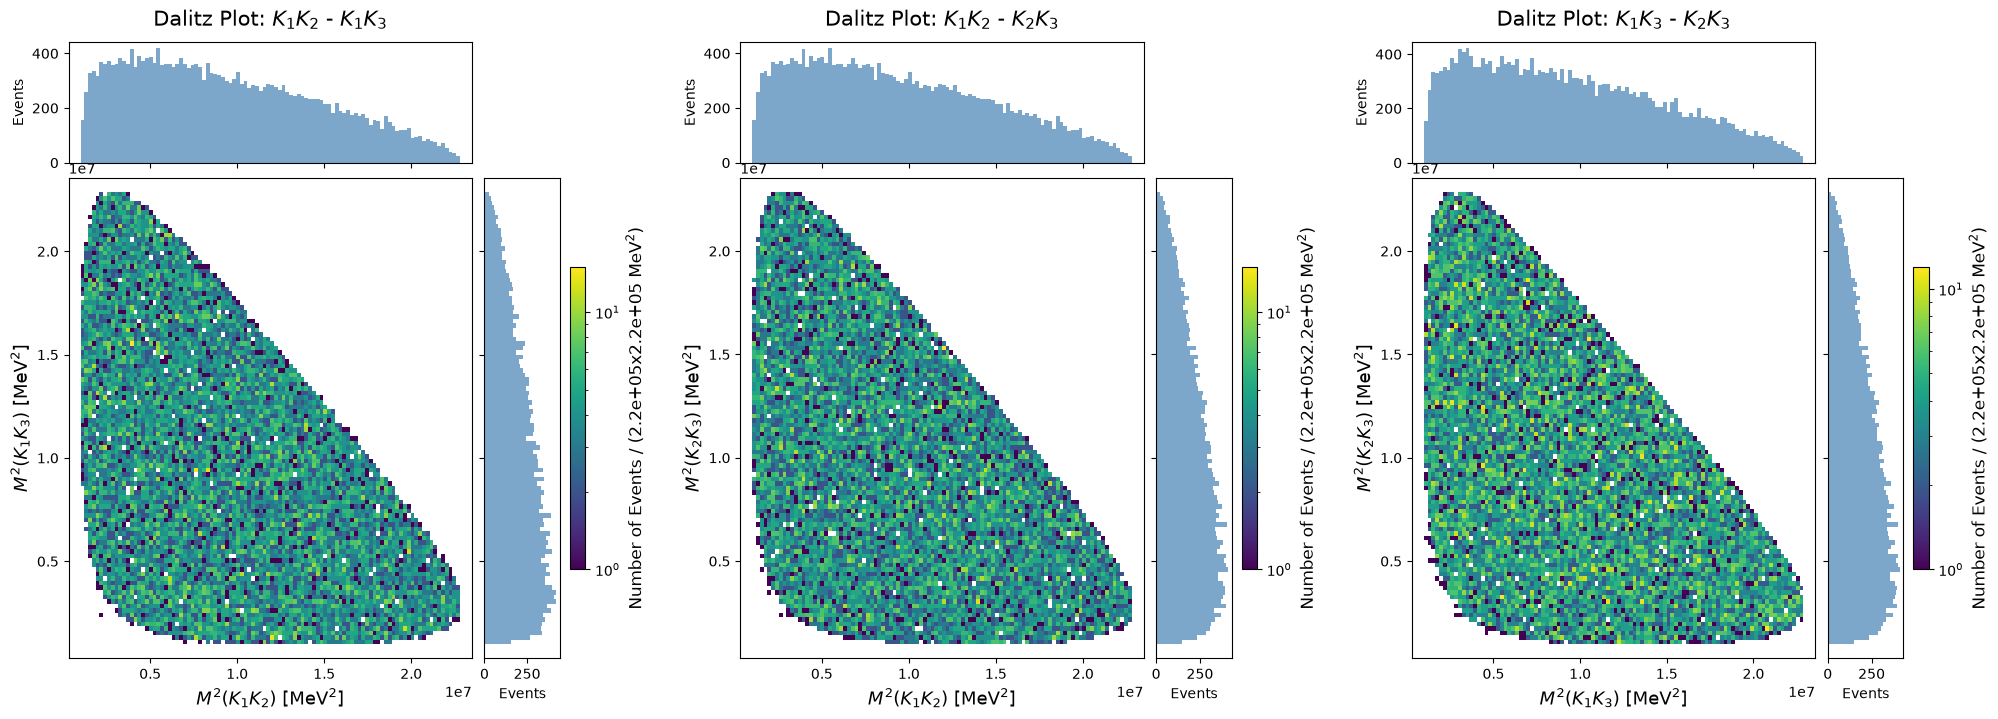

In [39]:
df_sim_charge_split = lf.split_by_charge(df_sim, col=df_sim.columns)
fig = lf.dalitz_plot(cfg, data=df_sim,                     bins=100)
fig = lf.dalitz_plot(cfg, data=df_sim_charge_split['pos'], bins=100)
fig = lf.dalitz_plot(cfg, data=df_sim_charge_split['neg'], bins=100)

### Real Data

#### Basic Dalitz Plot

In [40]:
# For Real Data the charge of 2 and 3 is the same (also equal to B charge)
#    --> 12 = 0
#    --> 13 = 0
#    --> 23 = ++/-- (should be no peak of M_23 in the Dalitz Plot) --> OK!

data[['H1_Charge', 'H2_Charge', 'H3_Charge', 'B_Charge']][:5]

,H1_Charge,H2_Charge,H3_Charge,B_Charge
0,-1,1,1,1
1,1,-1,-1,-1
2,-1,1,1,1
3,-1,1,1,1
4,1,-1,-1,-1


In [41]:
# # apply a cut on the B mass values (signal) to reduce the bkg
# data_signal = lf.select_window(data, cfg.sig_region)
# data_signal = data
# # plt.hist(data_signal['B_Mass'], bins=100);

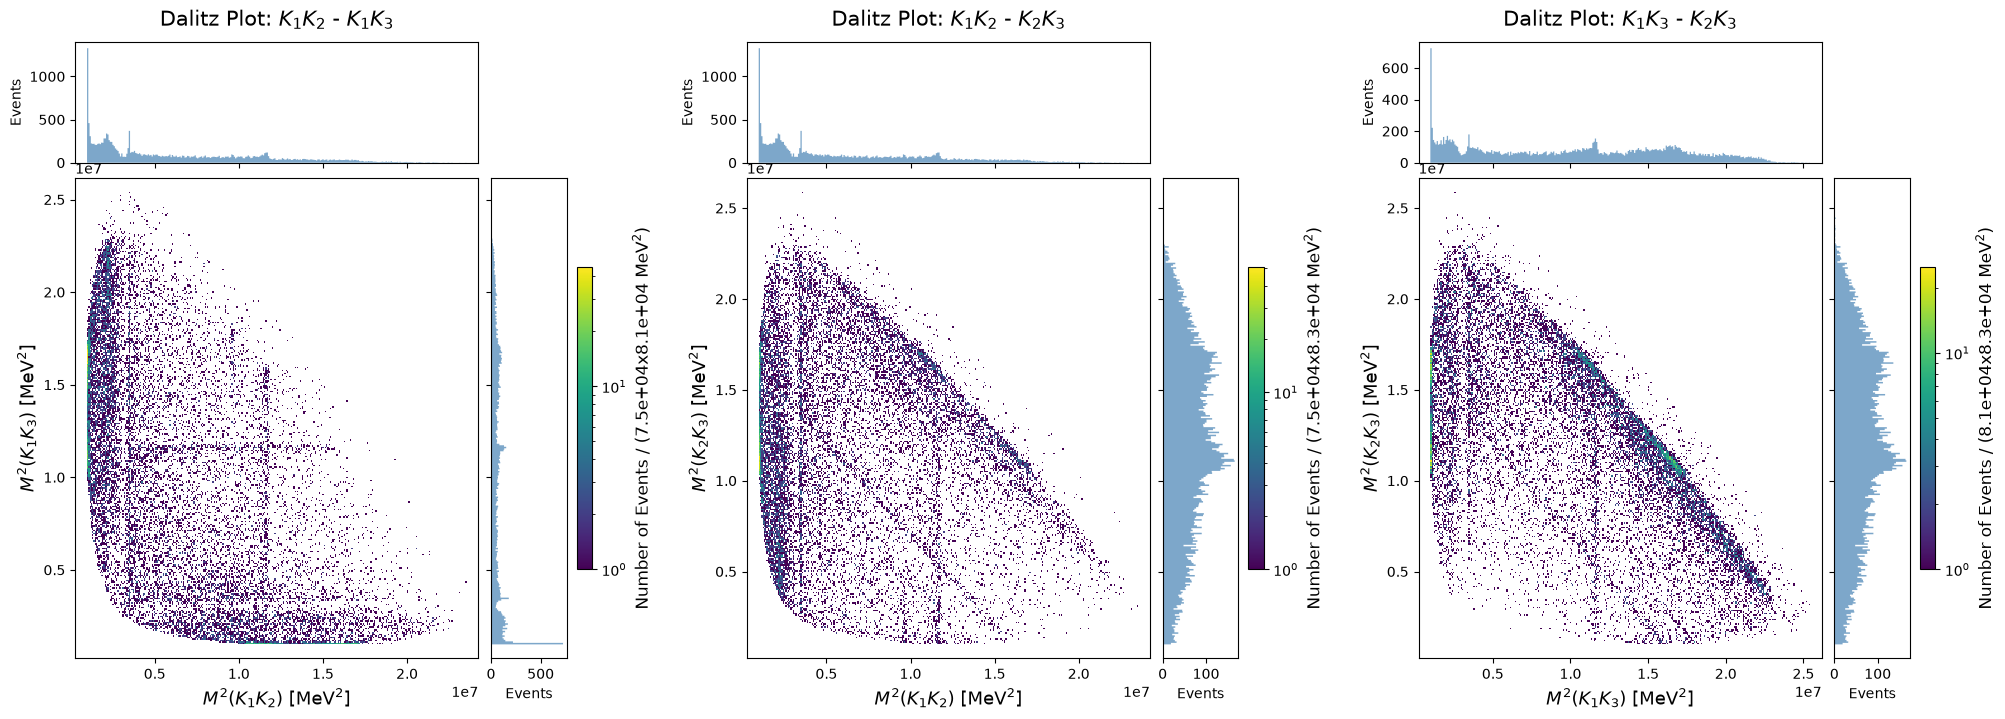

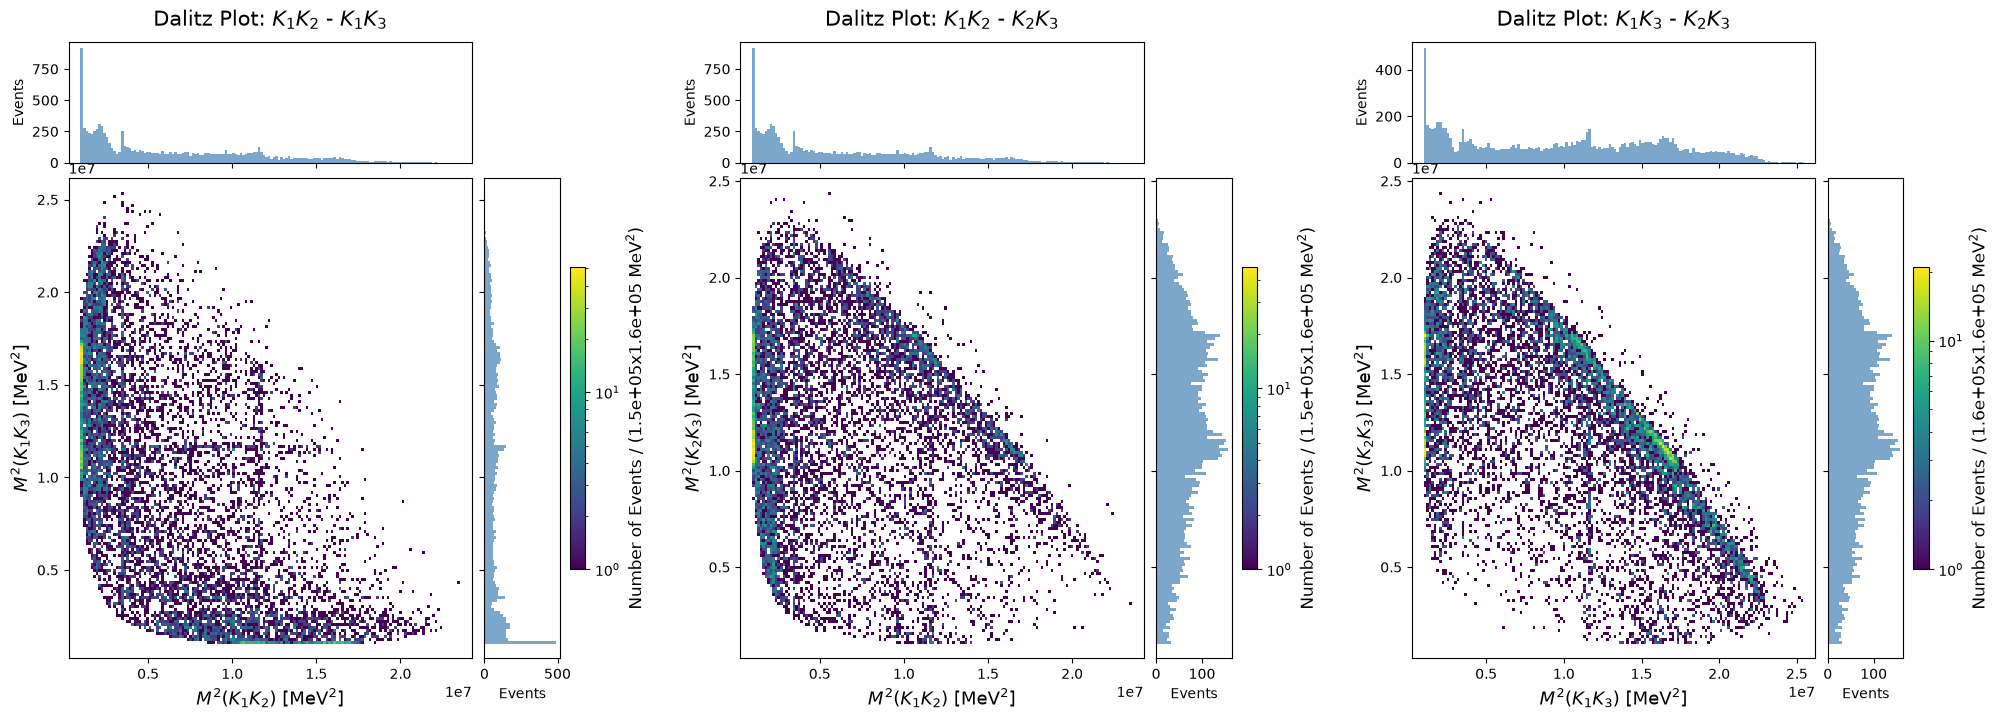

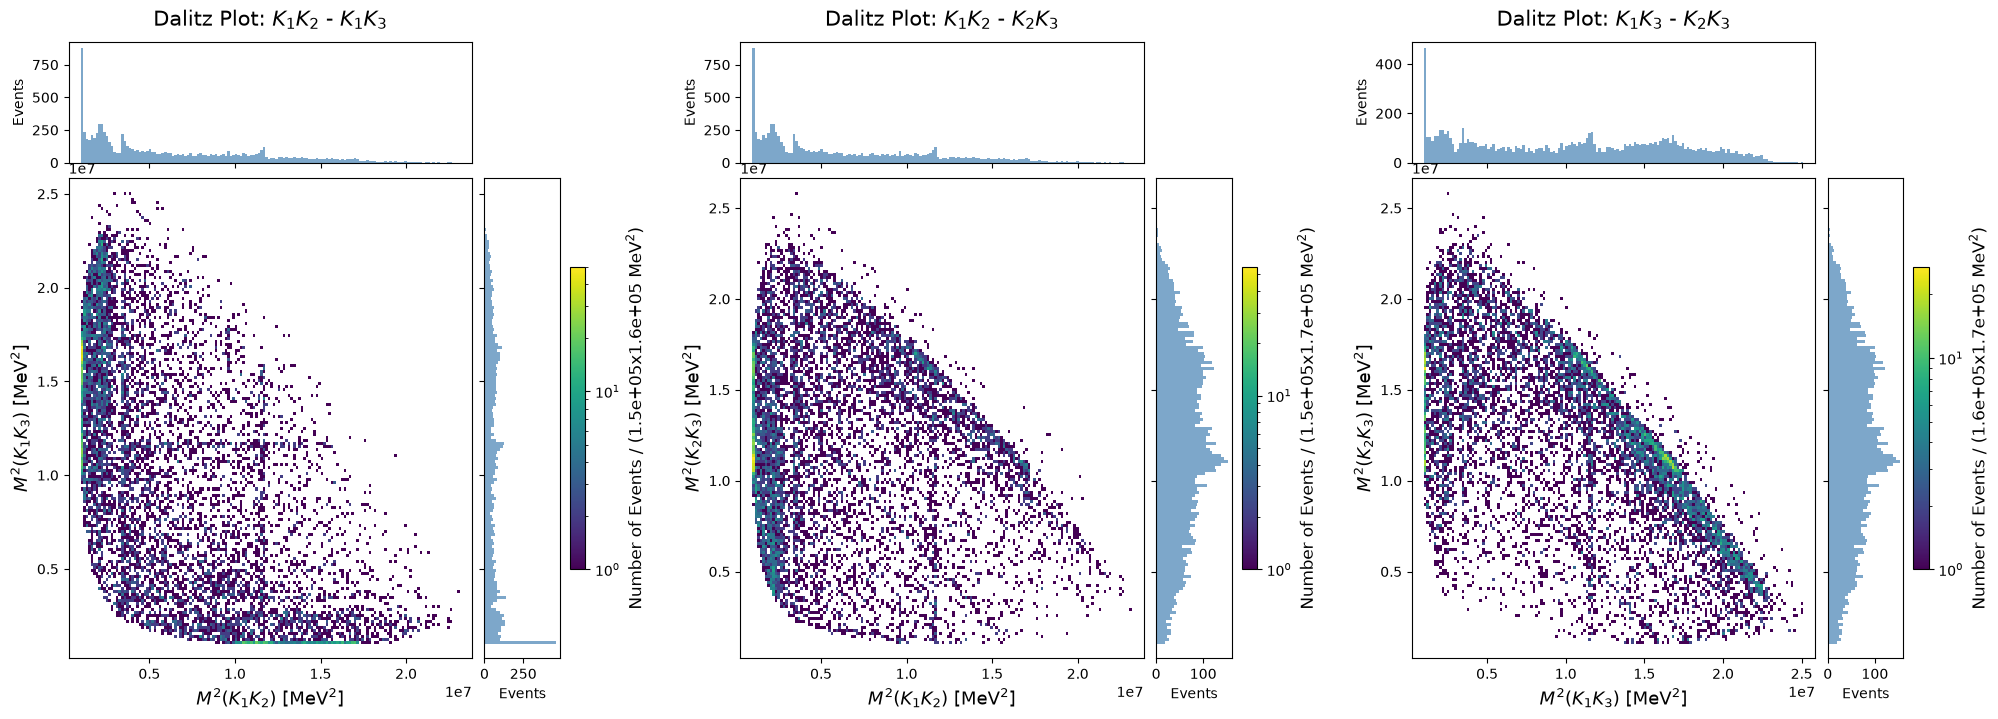

In [42]:
data_charge_split = lf.split_by_charge(data_window, col=data.columns)
fig, *_ = lf.dalitz_plot(cfg, data=data_window,              bins=300)
fig, *_ = lf.dalitz_plot(cfg, data=data_charge_split['pos'], bins=150)
fig, *_ = lf.dalitz_plot(cfg, data=data_charge_split['neg'], bins=150)

B charge:  pos
   Mass:  1865.475810617763 MeV
   Mass:  3398.529093593286 MeV
B charge:  neg


   Mass:  1865.475810617763 MeV
   Mass:  3398.529093593286 MeV


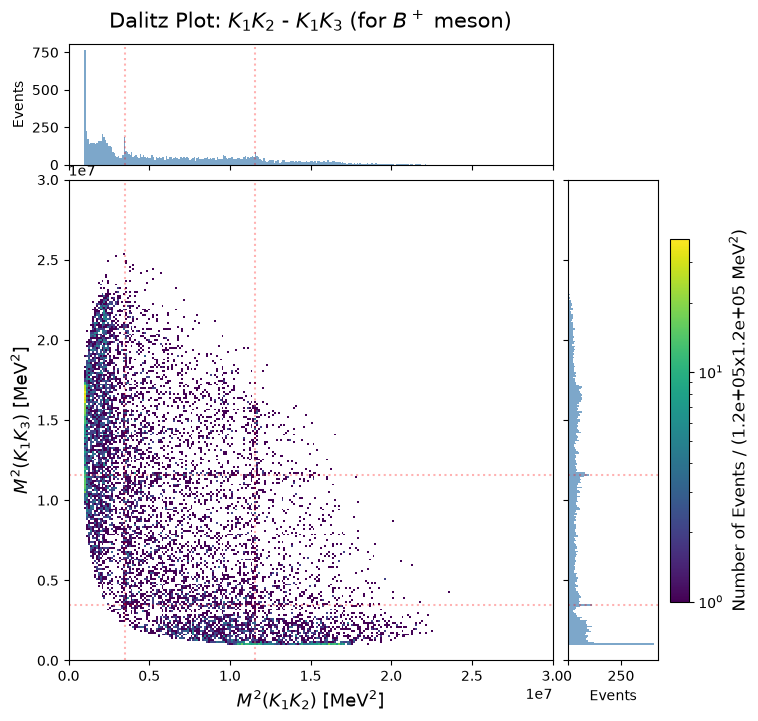

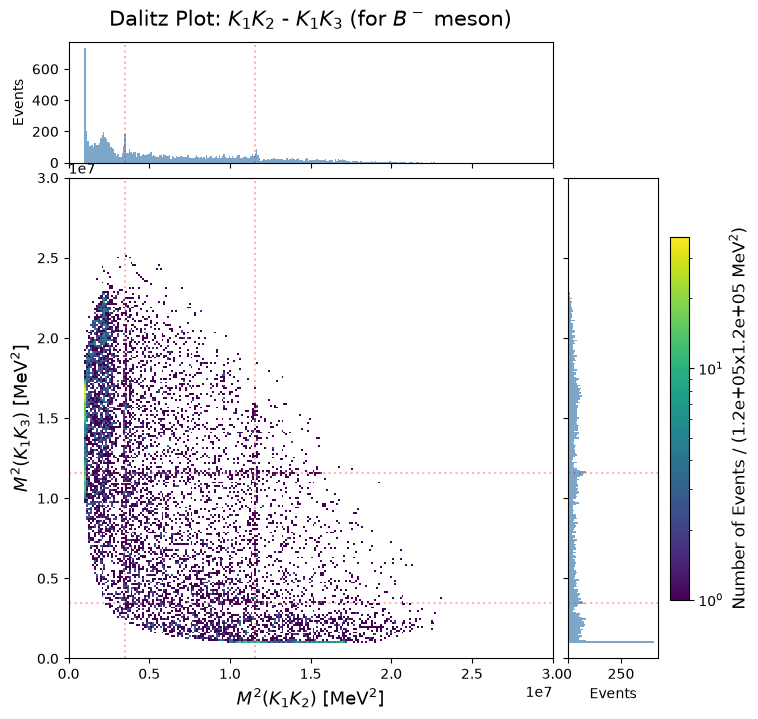

In [43]:
for charge, data_split in data_charge_split.items():
    print("B charge: ", charge)
    interesting_mass = {}
    all_mass = {f'{i}{j}': lf.invariant_mass(data_split, cfg, particles=(i,j)) for i,j in list(itertools.combinations(cfg.particles, 2))}
    interesting_mass['12'] = all_mass['12']
    interesting_mass['13'] = all_mass['13']

    fig, ax, ax_top, ax_left, *_ = lf.dalitz_plot(cfg, mass=interesting_mass, bins=250, range=[[0,3e7],[0,3e7]],
                                                    add_title=r' (for $B^+$ meson)' if charge=='pos' else r' (for $B^-$ meson)')

    possible_peaks = [0.348e7, 1.155e7]
    for possible_peak in possible_peaks:
        ax.axvline(possible_peak, 0,1, color='r', linestyle=':', alpha=0.3);
        ax.axhline(possible_peak, 0,1, color='r', linestyle=':', alpha=0.3);
        ax_top.axvline(possible_peak, 0,1, color='r', linestyle=':', alpha=0.3);
        ax_left.axhline(possible_peak, 0,1, color='r', linestyle=':', alpha=0.3);
        print("   Mass: ", np.sqrt(possible_peak), "MeV")

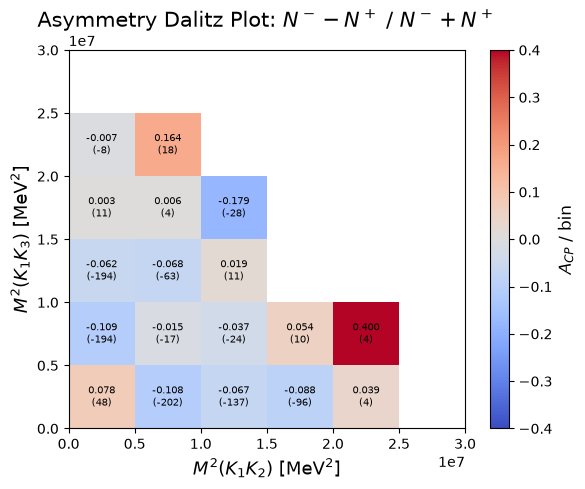

/var/folders/2r/cxn1cvbn4s5_ychznfzgynd00000gn/T/ipykernel_62008/4121470509.py:61: RuntimeWarning: invalid value encountered in divide
  histo_significance_masked = np.ma.masked_where(np.abs(histo_diff) <= 1, abs(histo_A_CP/histo_err_A_CP))
/var/folders/2r/cxn1cvbn4s5_ychznfzgynd00000gn/T/ipykernel_62008/4121470509.py:73: RuntimeWarning: invalid value encountered in scalar divide
  val2 = abs(histo_A_CP[i, j] / histo_err_A_CP[i, j])


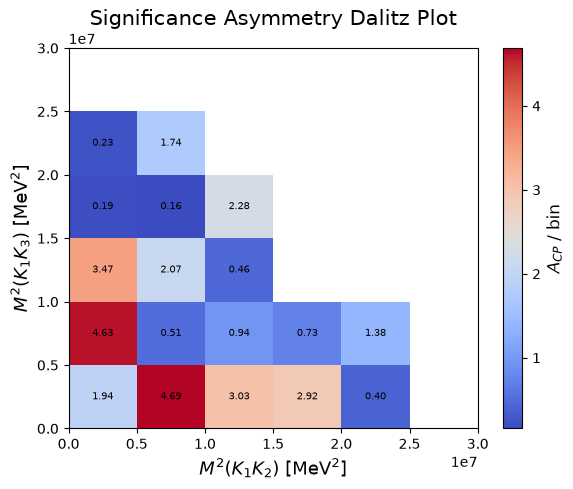

In [44]:
bins_histo_asymm=6

histo = {}
for charge, data_split in data_charge_split.items():
    # print("B charge: ", charge)
    interesting_mass = {}
    all_mass = {f'{i}{j}': lf.invariant_mass(data_split, cfg, particles=(i,j)) for i,j in list(itertools.combinations(cfg.particles, 2))}
    interesting_mass['12'] = all_mass['12']
    interesting_mass['13'] = all_mass['13']

    fig, ax, ax_top, ax_left, *histo[charge] = lf.dalitz_plot(cfg, mass=interesting_mass, bins=bins_histo_asymm, range=[[0,3e7],[0,3e7]],
                                                    add_title=r' (for $B^+$ meson)' if charge=='pos' else r' (for $B^-$ meson)')
    plt.close()


x_centers = np.array((histo['neg'][1][:-1] + histo['neg'][1][1:]) / 2)
y_centers = np.array((histo['neg'][2][:-1] + histo['neg'][2][1:]) / 2)

with np.errstate(divide='ignore', invalid='ignore'):
    histo_diff = histo['neg'][0] - histo['pos'][0]
    histo_A_CP, histo_err_A_CP = lf.raw_asymmetry(histo['pos'][0], histo['neg'][0])
    histo_A_CP = np.nan_to_num(histo_A_CP, nan=0.0)
    histo_err_A_CP = np.nan_to_num(histo_err_A_CP, nan=0.0)

histo_A_CP_masked = np.ma.masked_where(np.abs(histo_diff) <= 1, histo_A_CP)
fig, ax = plt.subplots(figsize=(6, 5))

im = ax.pcolormesh(
    histo['pos'][1], histo['pos'][2], histo_A_CP_masked.T,
    cmap='coolwarm', 
    norm=CenteredNorm(vcenter=0)
)
for i in np.arange(len(x_centers)):
    for j in np.arange(len(y_centers)):
        val1 = histo_diff[i, j]
        val2 = histo_A_CP[i, j]
        err_val2 = histo_err_A_CP[i, j]
        
        if abs(val1) > 1:
            ax.text(
                x_centers[i],
                y_centers[j],
                f"{val2:.3f}\n({int(val1)})",
                ha='center',
                va='center',
                fontsize=7,
                color='black'
            )

ax.set_xlabel(r"$M^2(K_1K_2)$ [MeV$^2$]", fontsize=13)
ax.set_ylabel(r"$M^2(K_1K_3)$ [MeV$^2$]", fontsize=13)
ax.set_title(r"Asymmetry Dalitz Plot: $N^- - N^+$ / $N^- + N^+$", fontsize=15)

cbar = fig.colorbar(im, ax=ax)
cbar.set_label(r"$A_{CP}$ / bin", fontsize=12)
fig.tight_layout()
plt.show()

# -----------------------------------------------------------------------------------------------------------

histo_significance_masked = np.ma.masked_where(np.abs(histo_diff) <= 1, abs(histo_A_CP/histo_err_A_CP))

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.pcolormesh(
    histo['pos'][1], histo['pos'][2], histo_significance_masked.T, 
    cmap='coolwarm', 
    # norm=CenteredNorm(vcenter=0)
)

for i in np.arange(len(x_centers)):
    for j in np.arange(len(y_centers)):
        val1 = histo_diff[i, j]
        val2 = abs(histo_A_CP[i, j] / histo_err_A_CP[i, j])
        if abs(val1) > 1:
            ax.text(
                x_centers[i],
                y_centers[j],
                f"{val2:.2f}",
                ha='center',
                va='center',
                fontsize=7,
                color='black'
            )

ax.set_xlabel(r"$M^2(K_1K_2)$ [MeV$^2$]", fontsize=13)
ax.set_ylabel(r"$M^2(K_1K_3)$ [MeV$^2$]", fontsize=13)
ax.set_title(r"Significance Asymmetry Dalitz Plot", fontsize=15)

cbar = fig.colorbar(im, ax=ax)
cbar.set_label(r"$A_{CP}$ / bin", fontsize=12)
fig.tight_layout()
plt.show()

#### Removing Charm Resonances

**Dalitz Plot**

B charge:  pos
B charge:  neg


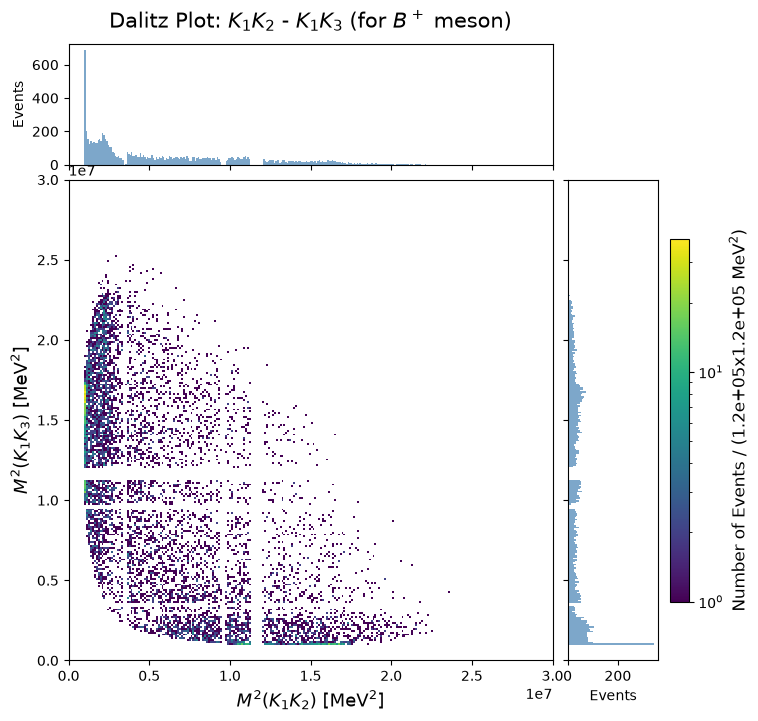

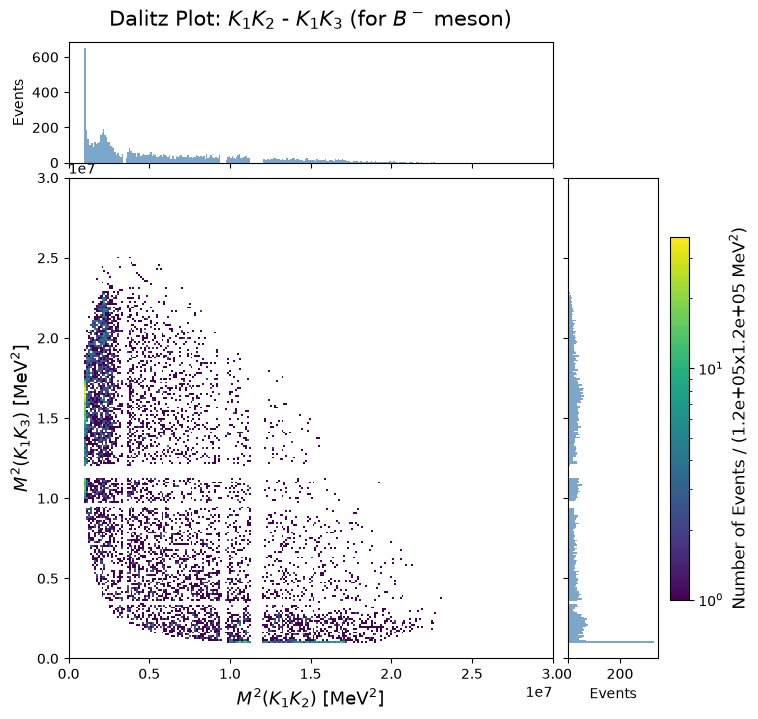

In [45]:
data_charge_split = lf.split_by_charge(data_window, col=data.columns)
for charge, data_split in data_charge_split.items():
    print("B charge: ", charge)
    interesting_mass = {}
    all_mass = {f'{i}{j}': lf.invariant_mass(data_split, cfg, particles=(i,j)) for i,j in list(itertools.combinations(cfg.particles, 2))}
    interesting_mass['12'] = all_mass['12']
    interesting_mass['13'] = all_mass['13']

    fig, ax, ax_top, ax_left, *_ = lf.dalitz_plot(cfg, mass=interesting_mass, bins=250, range=[[0,3e7],[0,3e7]], remove_resonances=['D', 'J', 'chi'],
                                                    add_title=r' (for $B^+$ meson)' if charge=='pos' else r' (for $B^-$ meson)')

**Asymmetry without Resonances**


=== veto 'D': 18744 candidates ===  valid: True
A_CP = -0.0493 ± 0.0087   (relative error 17.6%, Hesse significance 5.68 sigma)
Chi2:         431.73
NDOF:         388
Chi2 / NDOF:  1.113
p-value:      0.0620


H0: A_CP = 0  ->  t = 32.30,  p-value = 1.32e-08  (Z = sqrt(t) = 5.68 sigma)



=== veto 'all': 16367 candidates ===  valid: True
A_CP = -0.0421 ± 0.0094   (relative error 22.2%, Hesse significance 4.50 sigma)
Chi2:         421.11
NDOF:         388
Chi2 / NDOF:  1.085
p-value:      0.1190


H0: A_CP = 0  ->  t = 20.31,  p-value = 6.60e-06  (Z = sqrt(t) = 4.51 sigma)


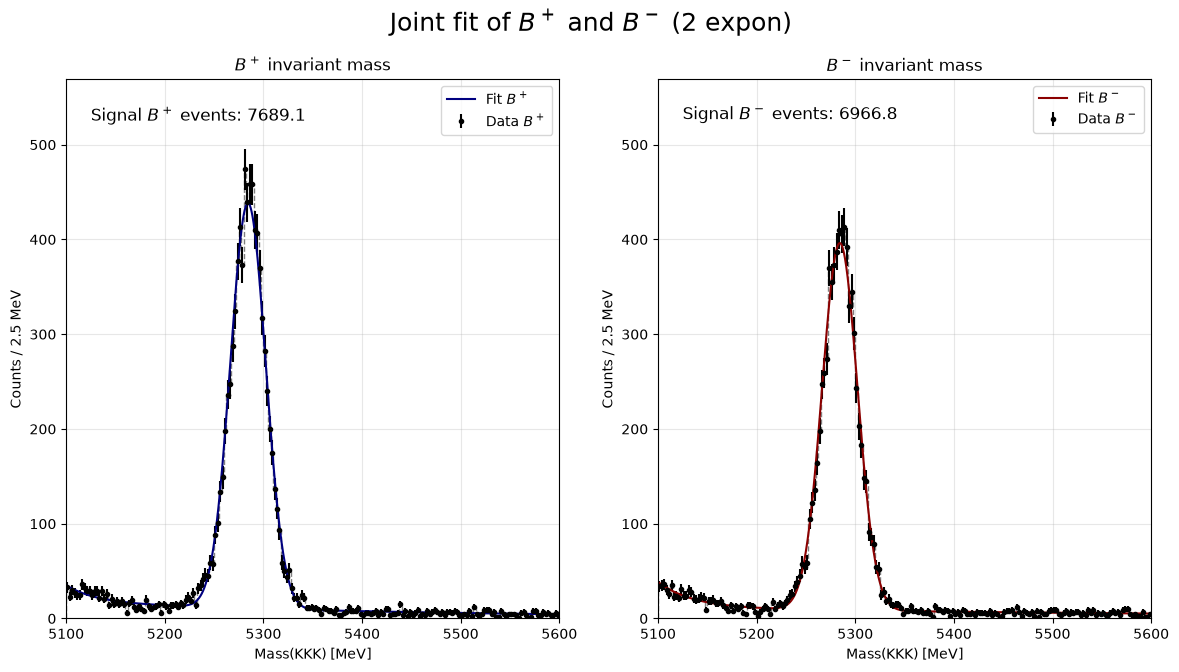

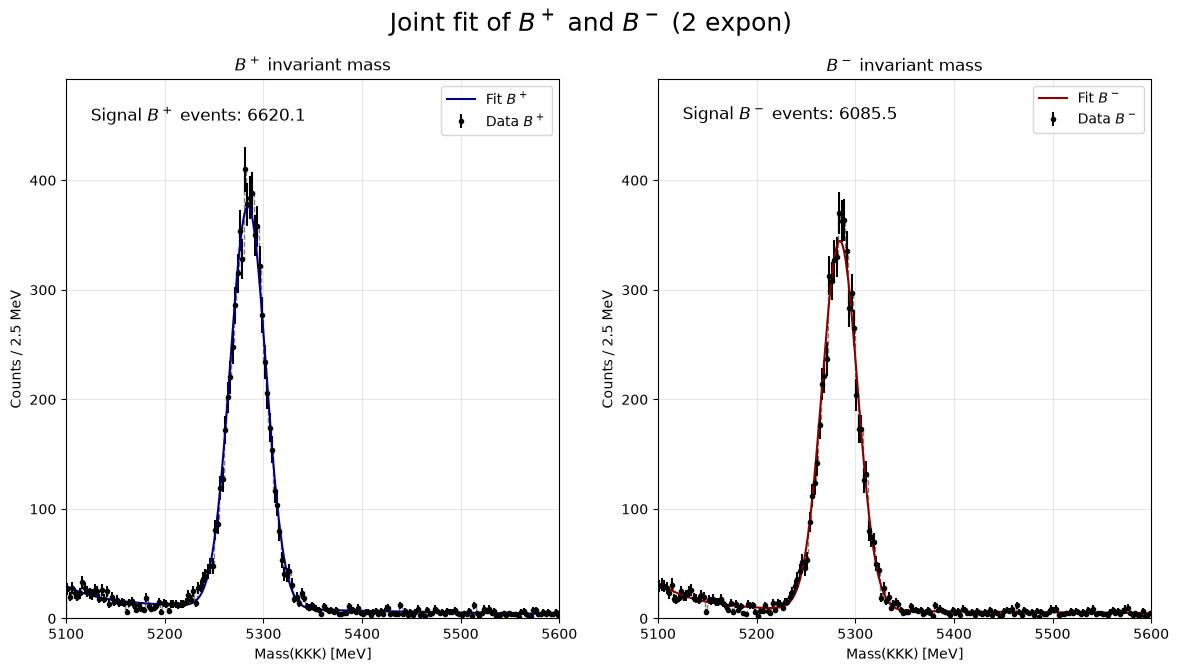

In [46]:
# [Giacomo, 2026-10-07] veto sul charm nelle due versioni concordate: 'D' (solo D0) e 'all' (D0 + J/psi + chi_c0).
# Control counts in the window [5100, 5600]: 18744 and 16367 candidates.
best_without_resonances = {}
for mode in ("D", "all"):
    data_without_resonances = lf.remove_charm_resonances(cfg, data_window, mode)
    samples_without_resonances = lf.split_by_charge(data_without_resonances, col='B_Mass')
    m = lf.fit_joint(samples_without_resonances, cfg, n_exp=2, minos=True)
    best_without_resonances[mode] = m
    print(f"\n=== veto '{mode}': {len(data_without_resonances)} candidates ===  valid: {m.valid}")
    lf.print_asymmetry(m)
    print(lf.gof_joint(m, samples_without_resonances, cfg, n_exp=2))
    lf.plot_joint_fit(m, samples_without_resonances, cfg, n_exp=2)
    t, p, _ = lf.wilks_test(m, {"A_CP": 0.0})
    print(f"H0: A_CP = 0  ->  t = {t:.2f},  p-value = {p:.2e}  (Z = sqrt(t) = {np.sqrt(t):.2f} sigma)")

**Asymmetry Dalitz Plot**

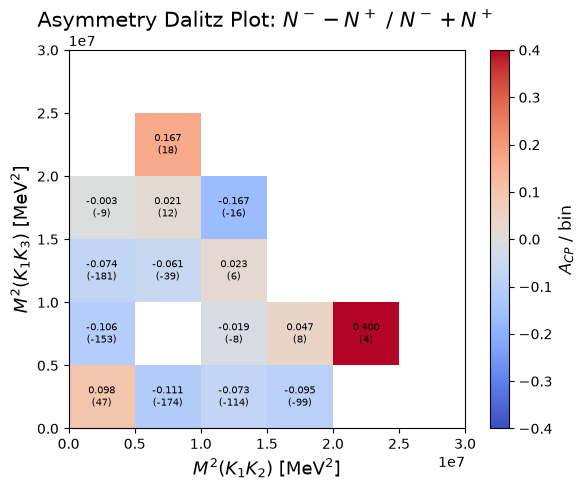

/var/folders/2r/cxn1cvbn4s5_ychznfzgynd00000gn/T/ipykernel_62008/3790051756.py:61: RuntimeWarning: divide by zero encountered in divide
  histo_significance_masked = np.ma.masked_where(np.abs(histo_diff) <= 1, abs(histo_A_CP/histo_err_A_CP))
/var/folders/2r/cxn1cvbn4s5_ychznfzgynd00000gn/T/ipykernel_62008/3790051756.py:61: RuntimeWarning: invalid value encountered in divide
  histo_significance_masked = np.ma.masked_where(np.abs(histo_diff) <= 1, abs(histo_A_CP/histo_err_A_CP))
/var/folders/2r/cxn1cvbn4s5_ychznfzgynd00000gn/T/ipykernel_62008/3790051756.py:73: RuntimeWarning: divide by zero encountered in scalar divide
  val2 = abs(histo_A_CP[i, j] / histo_err_A_CP[i, j])
/var/folders/2r/cxn1cvbn4s5_ychznfzgynd00000gn/T/ipykernel_62008/3790051756.py:73: RuntimeWarning: invalid value encountered in scalar divide
  val2 = abs(histo_A_CP[i, j] / histo_err_A_CP[i, j])


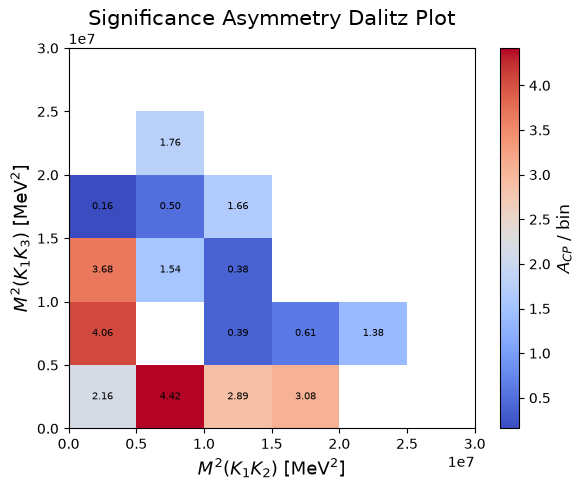

In [47]:
bins_histo_asymm=6

histo = {}
for charge, data_split in data_charge_split.items():
    # print("B charge: ", charge)
    interesting_mass = {}
    all_mass = {f'{i}{j}': lf.invariant_mass(data_split, cfg, particles=(i,j)) for i,j in list(itertools.combinations(cfg.particles, 2))}
    interesting_mass['12'] = all_mass['12']
    interesting_mass['13'] = all_mass['13']

    fig, ax, ax_top, ax_left, *histo[charge] = lf.dalitz_plot(cfg, mass=interesting_mass, bins=bins_histo_asymm, range=[[0,3e7],[0,3e7]], remove_resonances=['D', 'J', 'chi'],
                                                    add_title=r' (for $B^+$ meson)' if charge=='pos' else r' (for $B^-$ meson)')
    plt.close()


x_centers = np.array((histo['neg'][1][:-1] + histo['neg'][1][1:]) / 2)
y_centers = np.array((histo['neg'][2][:-1] + histo['neg'][2][1:]) / 2)

with np.errstate(divide='ignore', invalid='ignore'):
    histo_diff = histo['neg'][0] - histo['pos'][0]
    histo_A_CP, histo_err_A_CP = lf.raw_asymmetry(histo['pos'][0], histo['neg'][0])
    histo_A_CP = np.nan_to_num(histo_A_CP, nan=0.0)
    histo_err_A_CP = np.nan_to_num(histo_err_A_CP, nan=0.0)

histo_A_CP_masked = np.ma.masked_where(np.abs(histo_diff) <= 1, histo_A_CP)
fig, ax = plt.subplots(figsize=(6, 5))

im = ax.pcolormesh(
    histo['pos'][1], histo['pos'][2], histo_A_CP_masked.T,
    cmap='coolwarm', 
    norm=CenteredNorm(vcenter=0)
)
for i in np.arange(len(x_centers)):
    for j in np.arange(len(y_centers)):
        val1 = histo_diff[i, j]
        val2 = histo_A_CP[i, j]
        err_val2 = histo_err_A_CP[i, j]
        
        if abs(val1) > 1:
            ax.text(
                x_centers[i],
                y_centers[j],
                f"{val2:.3f}\n({int(val1)})",
                ha='center',
                va='center',
                fontsize=7,
                color='black'
            )

ax.set_xlabel(r"$M^2(K_1K_2)$ [MeV$^2$]", fontsize=13)
ax.set_ylabel(r"$M^2(K_1K_3)$ [MeV$^2$]", fontsize=13)
ax.set_title(r"Asymmetry Dalitz Plot: $N^- - N^+$ / $N^- + N^+$", fontsize=15)

cbar = fig.colorbar(im, ax=ax)
cbar.set_label(r"$A_{CP}$ / bin", fontsize=12)
fig.tight_layout()
plt.show()

# -----------------------------------------------------------------------------------------------------------

histo_significance_masked = np.ma.masked_where(np.abs(histo_diff) <= 1, abs(histo_A_CP/histo_err_A_CP))

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.pcolormesh(
    histo['pos'][1], histo['pos'][2], histo_significance_masked.T, 
    cmap='coolwarm', 
    # norm=CenteredNorm(vcenter=0)
)

for i in np.arange(len(x_centers)):
    for j in np.arange(len(y_centers)):
        val1 = histo_diff[i, j]
        val2 = abs(histo_A_CP[i, j] / histo_err_A_CP[i, j])
        if abs(val1) > 1:
            ax.text(
                x_centers[i],
                y_centers[j],
                f"{val2:.2f}",
                ha='center',
                va='center',
                fontsize=7,
                color='black'
            )

ax.set_xlabel(r"$M^2(K_1K_2)$ [MeV$^2$]", fontsize=13)
ax.set_ylabel(r"$M^2(K_1K_3)$ [MeV$^2$]", fontsize=13)
ax.set_title(r"Significance Asymmetry Dalitz Plot", fontsize=15)

cbar = fig.colorbar(im, ax=ax)
cbar.set_label(r"$A_{CP}$ / bin", fontsize=12)
fig.tight_layout()
plt.show()

#### Selecting Dalitz Plot Regions for A_CP Measurement

In [48]:
# [Giacomo, 2026-10-06] two notes on this selection:
# 1) the region is chosen by looking at the asymmetry map: the Wilks p-value computed afterwards does not account
#    for this choice (look-elsewhere), so it is exploratory (the a-priori region of the published analysis is used
#    in the report);
# 2) it uses UNORDERED m12^2 and m13^2: H2 and H3 are interchangeable, so a non-symmetric region selects events by an
#    arbitrary label. The report uses m^2_lo = min(m12^2, m13^2), m^2_hi = max(...).
# The significance of the bins of the maps above is computed with respect to zero; the report compares with the
# global asymmetry, (A_i - A_glob)/sigma_i.
cut_dalitz_mass = {}
for charge, data_split in data_charge_split.items():
    all_mass = {f'{i}{j}': lf.invariant_mass(data_split, cfg, particles=(i,j)) for i,j in list(itertools.combinations(cfg.particles, 2))}
    mask_dalitz_plot = (all_mass['12']**2 <= 1.0e7) & (all_mass['12']**2 >= 0.5e7) & (all_mass['13']**2 <= 0.5e7) & (all_mass['13']**2 >= 0.0e7)
    cut_dalitz_mass[charge] = data_split[mask_dalitz_plot]

events in fit window [5100.0, 5600.0] MeV: 1878
  B+ : 1040   B- : 838  -->  raw A_CP = -0.107561 ± 0.022942
  magnet down: 1096   magnet up: 782


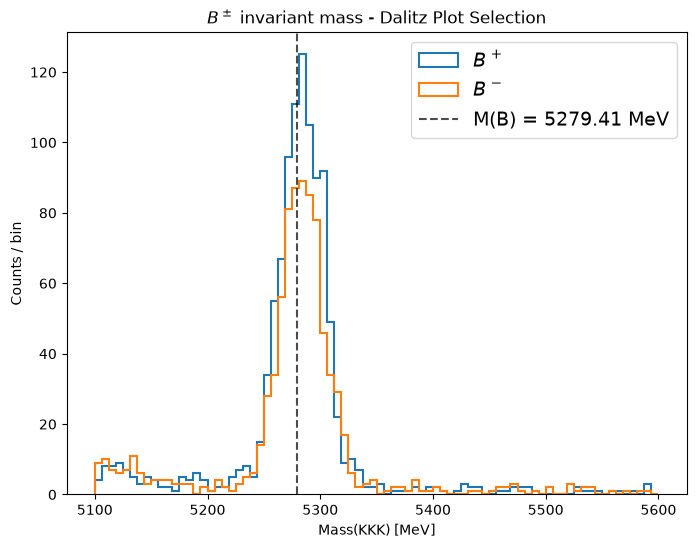

In [49]:
lf.plot_mass_by_charge(pd.concat([cut_dalitz_mass['pos'], cut_dalitz_mass['neg']], ignore_index=True), cfg, bins=80, bin_range=cfg.fit_window,
                       title=r"$B^\pm$ invariant mass - Dalitz Plot Selection")
lf.print_event_summary(pd.concat([cut_dalitz_mass['pos'], cut_dalitz_mass['neg']], ignore_index=True), cfg)

In [50]:
joint_cut_dalitz_mass = {n: lf.fit_joint({'pos': cut_dalitz_mass['pos']['B_Mass'], 'neg': cut_dalitz_mass['neg']['B_Mass']}, cfg, n_exp=n, minos=True) for n in (2, 1)}
display(joint_cut_dalitz_mass[1])

┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = -3327                      │             Nfcn = 1064              │
│ EDM = 5.65e-05 (Goal: 0.0002)    │            time = 0.8 sec            │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬───────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name      │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼───────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ N_sig     │  1.52e3   │  0.04e3   │  -0.04e3   │   0.04e3   │    0    │         │       │
│ 1 │ A_CP      │  -0.133   │   0.026   │   -0.026   │   0.026    │   -1    │    1    │       │
│ 2 │ mu        │ 5.2843e3  │ 0.0005e3  │ -0.0005e3  │  0.0005e3  │  5200   │  5350   │       │
│ 3 │ sigma     │   18.1    │    0.4    │    -0.4    │    0.4     │    1    │   100   │       │
│ 4 │ N_bkg_pos │    180    │    15     │    -15     │     16     │    0    │         │       │
│ 5 │ lam1_pos  │  4.8e-3   │  0.6e-3   │  -0.6e-3   │   0.6e-3   │  1e-06  │    1    │       │
│ 6 │ N_bkg_neg │    180    │    15     │    -15     │     16     │    0    │         │       │
│ 7 │ lam1_neg  │  5.1e-3   │  0.6e-3   │  -0.6e-3   │   0.6e-3   │  1e-06  │    1    │       │
└───┴───────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌──────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┐
│          │         N_sig         │         A_CP          │          mu           │         sigma         │       N_bkg_pos       │       lam1_pos        │       N_bkg_neg       │       lam1_neg        │
├──────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┤
│  Error   │    -40    │    40     │  -0.026   │   0.026   │   -0.5    │    0.5    │   -0.4    │    0.4    │    -15    │    16     │  -0.6e-3  │  0.6e-3   │    -15    │    16     │  -0.6e-3  │  0.6e-3   │
│  Valid   │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │
│ At Limit │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │
│ Max FCN  │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │
│ New Min  │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │
└──────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┘
┌───────────┬──────────────────────────────────────────────────────────────────────────────

In [51]:
# [Giacomo, 2026-10-07] region chosen by looking at the asymmetry map: EXPLORATORY result (look-elsewhere not included).
best_cut_dalitz_mass = joint_cut_dalitz_mass[2]
POIS = ["A_CP", "mu"]                                        # parameters of interest
nuisance = [p for p in best_cut_dalitz_mass.parameters if p not in POIS]     # everything else is profiled

t, p, _ = lf.wilks_test(best_cut_dalitz_mass, {"A_CP": 0.0})                 # H0: no CP violation
# [Giacomo, 2026-10-07] significance Z = sqrt(t) (likelihood ratio, one parameter), as in the report
print(f"H0: A_CP = 0  ->  t = {t:.2f},  p-value = {p:.2e}  (Z = sqrt(t) = {np.sqrt(t):.2f} sigma)")

H0: A_CP = 0  ->  t = 22.93,  p-value = 1.68e-06  (Z = sqrt(t) = 4.79 sigma)
